# 2. Modelado predictivo del grado tumoral (LGG vs. GBM)

El análisis exploratorio identificó un panel reducido de variables con asociación clara con el grado tumoral (`IDH1`, `Age_at_diagnosis`, `PTEN`, `ATRX`, `CIC`, `EGFR`…) y descartó problemas de multicolinealidad (VIF máximo de 3,09). Este capítulo traduce esos hallazgos en un clasificador: estima qué tan bien se puede distinguir un glioma de bajo grado (LGG) de un glioblastoma (GBM) a partir de tres variables clínicas y veinte mutaciones, y qué variables sostienen esa capacidad.

Se comparan tres familias de modelos con supuestos muy distintos:

- **Regresión logística** con regularización L1 o L2: lineal en el log-odds, interpretable coeficiente a coeficiente; es la línea base.
- **Random Forest**: promedio de árboles decorrelacionados (*bagging* + submuestreo de variables); captura interacciones sin especificarlas.
- **XGBoost**: árboles construidos de forma secuencial, cada uno corrigiendo el error del anterior (*gradient boosting*), con regularización explícita.

Cada modelo se combina con cuatro estrategias de balanceo y cuatro métodos de optimización de hiperparámetros, y todas las combinaciones se evalúan con validación cruzada anidada. El conjunto de prueba que el EDA reservó (168 pacientes) solo se usa al final, una vez elegidos los modelos.

:::{note}
El código reutilizable del capítulo está en el paquete `jbook/modelado/` (carga de datos, pipelines, espacios de búsqueda, optimizadores, pruebas estadísticas y gráficos, todos con *docstrings*). El experimento combinatorio se ejecuta con `python -m modelado.experimentos` y deja sus resultados en `jbook/resultados/`; este notebook los lee, de modo que puede reejecutarse en minutos. Con `RECALCULAR = True` se repite todo desde cero.
:::

## 2.1 Configuración y datos

In [1]:
# Librerías
## Librerías estándar de Python
import cProfile
import io
import json
import pickle
import pstats
import sys
import time
import tracemalloc
import warnings
from pathlib import Path

## NumPy, Pandas y visualización
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Estadística y Machine Learning
from scipy import stats
from scipy.stats import randint
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import (HalvingRandomSearchCV, RandomizedSearchCV,
                                     StratifiedKFold, cross_val_score)
import xgboost as xgb
from lime.lime_tabular import LimeTabularExplainer

## Jupyter
from IPython.display import HTML, display

## Paquete del capítulo (jbook/modelado). La ruta se resuelve tanto si el
## notebook se ejecuta desde jbook/ como desde la raíz del proyecto.
RAIZ_LIBRO = Path.cwd() if (Path.cwd() / "modelado").exists() else Path.cwd() / "jbook"
sys.path.insert(0, str(RAIZ_LIBRO))

from modelado import config, datos, modelos
from modelado import evaluacion as ev
from modelado import experimentos as exp
from modelado import graficos as gr
from modelado import optimizacion as opt
from modelado.utilidades import en_cache

warnings.filterwarnings("ignore")
gr.estilo()
np.random.seed(config.SEED)

# False: reutiliza lo guardado en jbook/resultados/.  True: recalcula todo
# (unas dos horas en un portátil de dos núcleos).
RECALCULAR = False

N = config.NOMBRES
CORTO = {"logistica": "RL", "random_forest": "RF", "xgboost": "XGB",
         "ninguno": "Sin", "smote": "SMOTE", "adasyn": "ADASYN", "class_weight": "CW",
         "grid": "Grid", "random": "Random", "bayesiano": "TPE", "genetico": "GA"}

### Entorno y semilla

La reproducibilidad depende de dos cosas: una semilla única y las versiones exactas de las librerías. La semilla global (`config.SEED = 42`, la misma del EDA) se pasa explícitamente a la partición, a cada `StratifiedKFold`, a los modelos, a los muestreadores de balanceo, al muestreador TPE de Optuna y al generador del algoritmo genético. Las versiones se registran junto a los resultados en `resultados/entorno.json` y se fijan en `jbook/requirements.txt`.

In [2]:
entorno = json.loads((config.DIR_RESULTADOS / "entorno.json").read_text())
pd.DataFrame(entorno.items(), columns=["Componente", "Versión / valor"]).set_index("Componente")

,Versión / valor
Componente,
python,3.12.14
plataforma,Windows-11-10.0.26300-SP0
numpy,2.5.3
pandas,3.0.5
scipy,1.18.1
scikit-learn,1.9.1
imbalanced-learn,0.14.2
xgboost,3.4.1
optuna,5.0.0


### Partición y predictoras

La partición se reconstruye con la función `datos.particion()`, que replica exactamente la del EDA: mismo archivo, 80/20 estratificado por `Grade` y `random_state = 42`. Por eso los 168 pacientes de prueba son los mismos que el análisis exploratorio nunca miró.

In [3]:
X_train, X_test, y_train, y_test = datos.particion()
X_train, y_train = X_train.reset_index(drop=True), y_train.reset_index(drop=True)

particion = pd.DataFrame({
    "Pacientes": [len(y_train), len(y_test)],
    "LGG (0)": [(y_train == 0).sum(), (y_test == 0).sum()],
    "GBM (1)": [(y_train == 1).sum(), (y_test == 1).sum()],
}, index=["Entrenamiento", "Prueba"])
particion["% GBM"] = (particion["GBM (1)"] / particion["Pacientes"] * 100).round(1)
particion

,Pacientes,LGG (0),GBM (1),% GBM
Entrenamiento,671,389,282,42.0
Prueba,168,98,70,41.7


Las 23 predictoras entran completas a los modelos. El EDA mostró que ninguna es reconstruible a partir de las demás (VIF máximo 3,09), así que no hay razón técnica para eliminar variables antes de modelar; descartar las de asociación débil a priori sería, además, una decisión tomada con los mismos datos que luego se usan para validar. En su lugar, la regularización (L1 en la logística, profundidad y tamaño de hoja en los árboles) decide cuánto peso recibe cada una, y la sección 2.11 estudia cuántas variables hacen falta realmente.

| Variable | Tipo | Preprocesamiento (dentro del pipeline) |
|---|---|---|
| `Age_at_diagnosis` | Continua | Estandarización con la media y la desviación del pliegue de entrenamiento |
| `Gender` | Binaria | Ninguno (0 = hombre, 1 = mujer) |
| `Race_binary` | Binaria | Agrupación del EDA: 0 = White, 1 = otros grupos (las categorías Asian y American Indian tienen 14 y 1 pacientes) |
| 20 genes | Binarias | Ninguno (0 = no mutado, 1 = mutado) |

## 2.2 Diseño experimental

### Explosión combinatoria

El proyecto no consiste en entrenar un modelo, sino en recorrer de forma sistemática todas las combinaciones de tres decisiones:

| Etapa | Alternativas | n |
|---|---|---|
| 1. Modelo base | Regresión Logística (L1/L2), Random Forest, XGBoost | 3 |
| 2. Balanceo de clases | Sin balanceo, SMOTE-NC, ADASYN, `class_weight='balanced'` | 4 |
| 3. Optimización de hiperparámetros | Grid Search, Random Search, Bayesiana (Optuna, TPE), Genética (DEAP) | 4 |
| **Total** | $3 \times 4 \times 4$ | **48** |

Cada una de las 48 combinaciones se entrena y evalúa de forma independiente dentro de una validación cruzada anidada de $10 \times 3$ pliegues con 24 evaluaciones de hiperparámetros por búsqueda: en total 11 520 configuraciones probadas y 34 560 ajustes internos. El experimento está automatizado con bucles anidados (`experimentos.correr()`), y cada corrida queda registrada en una tabla maestra (`resultados/experimentos.csv`) con su modelo, balanceo, optimizador, métricas del bucle externo, tiempos y semilla, y en `resultados/pliegues.csv` con los hiperparámetros elegidos en cada pliegue.

### Validación cruzada anidada

Elegir hiperparámetros mirando el desempeño en unos datos y reportar ese mismo desempeño sobreestima la capacidad del modelo (sesgo de selección). La validación anidada separa las dos tareas:

- **Bucle externo (10 pliegues estratificados):** solo mide. En cada pliegue, 604 pacientes se usan para buscar y ajustar, y 67 (unos 28 GBM) para evaluar. La métrica que se reporta en todo el capítulo sale de aquí.
- **Bucle interno (3 pliegues estratificados):** dentro de los 604 pacientes de cada pliegue externo, cada configuración candidata se evalúa con una validación cruzada de 3 pliegues; el optimizador solo ve esta AUC interna.

Se eligieron **10 pliegues externos** porque con 671 pacientes cada pliegue de validación conserva unos 28 GBM, suficientes para una AUC estable, y porque las pruebas de Friedman y Nemenyi de la sección 2.10 usan los pliegues como bloques: con 5 pliegues la diferencia crítica sería tan grande que ninguna comparación tendría potencia. En el bucle interno bastan **3 pliegues**: cada validación interna tiene unos 200 pacientes y el costo total se multiplica por $K_\text{int}$ en cada una de las 11 520 evaluaciones.

### Métrica de validación

El criterio que guía la búsqueda es el **área bajo la curva ROC (AUC)**. Es independiente del umbral de decisión, no se distorsiona con el desbalance moderado del problema (58 % LGG / 42 % GBM) y mide lo que se busca: ordenar a los pacientes por riesgo de GBM. Como métrica clínica secundaria se sigue de cerca el **recall de GBM** (sensibilidad): clasificar un glioblastoma como glioma de bajo grado retrasa un tratamiento agresivo, mientras que el error contrario lleva a pruebas adicionales; un falso negativo es más costoso que un falso positivo. Se reportan además accuracy, precision, F1 y Brier.

### Balanceo de clases

La relación de clases es de 1,38 a 1, un desbalance leve. Se comparan cuatro estrategias, siempre aplicadas **dentro** del pipeline, de modo que nunca se generan pacientes sintéticos a partir de pacientes de validación:

- **Sin balanceo:** línea base.
- **SMOTE-NC:** la variante de SMOTE para predictoras mixtas. Con 22 predictoras binarias, el SMOTE clásico generaría pacientes con valores imposibles (una mutación de 0,37); SMOTE-NC interpola solo la edad y asigna a cada variable binaria el valor más frecuente entre los vecinos.
- **ADASYN:** genera más pacientes sintéticos en las zonas donde la clase minoritaria es difícil de aprender. No tiene variante nominal, así que sí produce valores intermedios en las binarias; se mantiene como término de comparación.
- **`class_weight='balanced'`:** no crea datos; pondera cada error por el inverso de la frecuencia de su clase. En XGBoost el equivalente es `scale_pos_weight = n_LGG / n_GBM`, calculado en cada pliegue de entrenamiento.

### Espacios de búsqueda

Cada modelo tiene **un único** espacio de búsqueda del que se derivan las cuatro representaciones que piden los optimizadores (rejilla, distribuciones, sugerencias de Optuna y genoma), así que los cuatro métodos exploran el mismo dominio. Los parámetros de escala multiplicativa ($C$, *learning rate*, `min_child_weight`, $\lambda$) se muestrean en escala logarítmica. Los rangos se fijaron a partir del tamaño de los datos:

- **Regresión logística:** $C \in [10^{-3}, 10^{2}]$ cubre desde una regularización que anula casi todos los coeficientes hasta una prácticamente nula; L1 permite que el modelo descarte variables por sí mismo.
- **Random Forest:** con 600 pacientes, una profundidad mayor que 16 equivale a árboles sin límite; `min_samples_leaf` hasta 20 (≈ 3 % del pliegue) controla el sobreajuste; `max_features` en fracción de las 23 variables. El número de árboles se fija en 200: más árboles no sobreajustan, solo cuestan tiempo.
- **XGBoost:** árboles poco profundos (2–8) porque las señales principales (IDH1, edad) son casi aditivas; *learning rate* y número de árboles en rangos que mantienen su producto razonable; submuestreo de filas y columnas y regularización L2 como defensas adicionales contra el sobreajuste.

La rejilla de Grid Search tiene exactamente 24 puntos en los tres modelos, el mismo presupuesto que reciben los demás optimizadores. En XGBoost la rejilla no puede cubrir las siete dimensiones con 24 puntos, así que solo varía cuatro y deja las otras tres en su valor por defecto: es precisamente la limitación de Grid Search en espacios de alta dimensión que esta comparación quiere medir.

In [4]:
def _fmt(v):
    return f"{v:g}" if isinstance(v, (int, float, np.floating)) else str(v)

filas = []
for m, espacio in modelos.ESPACIOS.items():
    for p in espacio:
        dominio = (", ".join(p.opciones) if p.tipo == "cat"
                   else f"[{p.bajo:g}, {p.alto:g}]" + (" log" if p.log else ""))
        filas.append({"Modelo": N[m], "Hiperparámetro": p.nombre, "Tipo": p.tipo,
                      "Dominio (Random, TPE, Genético)": dominio,
                      "Rejilla (Grid)": ", ".join(_fmt(v) for v in p.rejilla) or "por defecto"})
pd.DataFrame(filas).set_index(["Modelo", "Hiperparámetro"])

Tipo Dominio (Random, TPE, Genético)  \
Modelo              Hiperparámetro                                            
Regresión Logística penalty             cat                          l1, l2   
                    C                 float                [0.001, 100] log   
Random Forest       max_depth           int                         [2, 16]   
                    min_samples_leaf    int                         [1, 20]   
                    max_features      float                        [0.1, 1]   
XGBoost             max_depth           int                          [2, 8]   
                    learning_rate     float                 [0.01, 0.3] log   
                    n_estimators        int                       [50, 400]   
                    min_child_weight  float                     [1, 10] log   
                    subsample         float                        [0.6, 1]   
                    colsample_bytree  float                        [0.5, 1]   
                    reg_lambda        float                  [0.01, 10] log   

                                                                         Rejilla (Grid)  
Modelo              Hiperparámetro                                                       
Regresión Logística penalty                                                      l1, l2  
                    C                 0.001, 0.00285, 0.00811, 0.0231, 0.06579, 0.18...  
Random Forest       max_depth                                               3, 5, 8, 16  
                    min_samples_leaf                                           1, 4, 10  
                    max_features                                               0.2, 0.5  
XGBoost             max_depth                                                   2, 3, 5  
                    learning_rate                                             0.03, 0.1  
                    n_estimators                                               100, 300  
                    min_child_weight                                               1, 5  
                    subsample                                               por defecto  
                    colsample_bytree                                        por defecto  
                    reg_lambda                                              por defecto

### Los cuatro optimizadores

Todos reciben **24 evaluaciones**, el mismo particionador interno y el mismo pipeline, así que la comparación es a presupuesto fijo.

**Grid Search** recorre la rejilla completa en orden. Es exhaustivo pero rígido: gasta el presupuesto en combinaciones fijas aunque una dimensión no importe.

**Random Search** muestrea 24 configuraciones independientes del dominio continuo. Bergstra y Bengio (2012) muestran que, cuando solo unas pocas dimensiones importan, explora cada una con más valores distintos que una rejilla del mismo tamaño.

**Optimización bayesiana (Optuna, TPE).** El preprocesamiento y el modelo se construyen como un pipeline completo dentro de la función objetivo, así cada evaluación ajusta el escalado y el balanceo solo con los datos de entrenamiento de cada pliegue interno.

- *Modelo sustituto:* **Tree-structured Parzen Estimator**. En lugar de modelar $p(\text{AUC} \mid \lambda)$ con un proceso gaussiano, divide las evaluaciones en un grupo "bueno" (cuantil superior $\gamma$) y uno "malo", y ajusta una densidad de Parzen a cada uno: $\ell(\lambda)$ y $g(\lambda)$. Escala bien a espacios con variables categóricas y enteras, como los de este problema.
- *Función de adquisición:* **Mejora Esperada (EI)**. Con el sustituto TPE, maximizar EI equivale a maximizar $\ell(\lambda)/g(\lambda)$ (Bergstra et al., 2011). Las primeras 8 evaluaciones son aleatorias (exploración pura); a partir de ahí el cociente favorece las regiones donde ya hubo buenas configuraciones (explotación), sin eliminar la exploración, porque los candidatos se muestrean de una densidad y no de un óptimo puntual.

**Algoritmo genético (DEAP).** Cada individuo es un vector de genes en $[0, 1]$, uno por hiperparámetro, que se decodifica al dominio real (lineal, logarítmico, entero o categórico). La evaluación de cada individuo es una validación cruzada interna del pipeline completo, sin fuga de información.

| Componente | Elección | Justificación |
|---|---|---|
| Selección | Torneo de tamaño 3 | Presión selectiva moderada que no depende de la escala de la aptitud: todas las AUC están entre 0,85 y 0,93 y una ruleta apenas distinguiría entre ellas |
| Cruce | *Blend* (BLX-α, α = 0,5), probabilidad 0,7 | Genera hijos dentro y alrededor del segmento entre los padres; adecuado para genes reales |
| Mutación | Gaussiana (σ = 0,2, probabilidad por gen 0,3), probabilidad 0,3 por individuo | Saltos de tamaño moderado que mantienen diversidad |
| Elitismo | Esquema $(\mu + \lambda)$ con $\mu = \lambda = 6$ y `HallOfFame` | La siguiente generación sale de padres e hijos juntos; el mejor individuo nunca se pierde |
| Presupuesto | 6 iniciales + 3 generaciones × 6 hijos = 24 | Igual al de los demás métodos; configuraciones repetidas se cachean y no consumen presupuesto |
| Diversidad | Distancia euclídea media entre genomas, normalizada por $\sqrt{d}$ | Si cae a cero antes de tiempo, hay convergencia prematura (sección 2.4) |

## 2.3 Resultados de la validación anidada

In [5]:
archivo = config.DIR_RESULTADOS / "experimentos.csv"
if RECALCULAR or not archivo.exists():
    exp.correr(n_jobs=2)

resumen = pd.read_csv(archivo)
pliegues = pd.read_csv(config.DIR_RESULTADOS / "pliegues.csv")
historiales = json.loads((config.DIR_RESULTADOS / "historiales.json").read_text())
geneticos = json.loads((config.DIR_RESULTADOS / "geneticos.json").read_text())
oof = pd.read_csv(config.DIR_RESULTADOS / "oof.csv")

n_eval = int(resumen["n_eval_total"].sum())
print(f"Combinaciones evaluadas: {len(resumen)}")
print(f"Pliegues externos:       {len(pliegues)}")
print(f"Configuraciones probadas: {n_eval:,} ({n_eval * config.K_INTERNO:,} ajustes internos)")
print(f"Tiempo de reloj total:   {resumen['t_total_s'].sum() / 60:.1f} min con 2 procesos")

Combinaciones evaluadas: 48
Pliegues externos:       480
Configuraciones probadas: 11,520 (34,560 ajustes internos)
Tiempo de reloj total:   134.8 min con 2 procesos


In [6]:
def media_de(df, m, dec=3):
    return (df[f"{m}_media"].map(lambda v: f"{v:.{dec}f}") + " ± "
            + df[f"{m}_de"].map(lambda v: f"{v:.{dec}f}"))

tabla_maestra = pd.DataFrame({
    "Modelo": resumen["modelo"].map(N), "Balanceo": resumen["balanceo"].map(N),
    "Optimizador": resumen["metodo"].map(N),
    "AUC": media_de(resumen, "auc"), "Recall GBM": media_de(resumen, "recall"),
    "Precision": media_de(resumen, "precision"), "F1": media_de(resumen, "f1"),
    "Brier": media_de(resumen, "brier"), "Tiempo (s)": resumen["t_total_s"].round(1),
    "_orden": resumen["auc_media"],
}).sort_values("_orden", ascending=False).drop(columns="_orden")
tabla_maestra.insert(0, "Puesto", range(1, len(tabla_maestra) + 1))

display(HTML("<p><b>Las 10 mejores combinaciones (media ± DE en los 10 pliegues externos)</b></p>"
             + tabla_maestra.head(10).to_html(index=False)))
HTML("<details><summary>Ver las 48 combinaciones</summary>"
     + tabla_maestra.to_html(index=False) + "</details>")

Puesto,Modelo,Balanceo,Optimizador,AUC,Recall GBM,Precision,F1,Brier,Tiempo (s)
1,Random Forest,ADASYN,Bayesiano (TPE),0.921 ± 0.039,0.926 ± 0.054,0.802 ± 0.057,0.858 ± 0.044,0.108 ± 0.027,315.1
2,Random Forest,class_weight,Bayesiano (TPE),0.920 ± 0.036,0.926 ± 0.051,0.810 ± 0.063,0.862 ± 0.044,0.104 ± 0.028,321.9
3,Random Forest,Sin balanceo,Grid Search,0.920 ± 0.040,0.911 ± 0.045,0.813 ± 0.055,0.857 ± 0.031,0.103 ± 0.029,156.6
4,Regresión Logística,Sin balanceo,Grid Search,0.919 ± 0.038,0.897 ± 0.074,0.813 ± 0.051,0.852 ± 0.051,0.103 ± 0.031,15.3
5,Regresión Logística,Sin balanceo,Genético (DEAP),0.919 ± 0.039,0.901 ± 0.077,0.811 ± 0.053,0.852 ± 0.052,0.104 ± 0.031,10.2
6,Regresión Logística,Sin balanceo,Bayesiano (TPE),0.919 ± 0.039,0.898 ± 0.084,0.805 ± 0.054,0.847 ± 0.057,0.104 ± 0.031,10.0
7,Regresión Logística,Sin balanceo,Random Search,0.919 ± 0.038,0.905 ± 0.072,0.817 ± 0.050,0.857 ± 0.050,0.103 ± 0.030,9.6
8,Random Forest,Sin balanceo,Bayesiano (TPE),0.918 ± 0.041,0.908 ± 0.056,0.812 ± 0.059,0.855 ± 0.039,0.103 ± 0.029,160.2
9,Regresión Logística,class_weight,Genético (DEAP),0.918 ± 0.037,0.922 ± 0.055,0.805 ± 0.057,0.859 ± 0.047,0.105 ± 0.030,8.9
10,Random Forest,Sin balanceo,Random Search,0.918 ± 0.039,0.908 ± 0.065,0.806 ± 0.057,0.852 ± 0.045,0.107 ± 0.028,170.2


Puesto,Modelo,Balanceo,Optimizador,AUC,Recall GBM,Precision,F1,Brier,Tiempo (s)
1,Random Forest,ADASYN,Bayesiano (TPE),0.921 ± 0.039,0.926 ± 0.054,0.802 ± 0.057,0.858 ± 0.044,0.108 ± 0.027,315.1
2,Random Forest,class_weight,Bayesiano (TPE),0.920 ± 0.036,0.926 ± 0.051,0.810 ± 0.063,0.862 ± 0.044,0.104 ± 0.028,321.9
3,Random Forest,Sin balanceo,Grid Search,0.920 ± 0.040,0.911 ± 0.045,0.813 ± 0.055,0.857 ± 0.031,0.103 ± 0.029,156.6
4,Regresión Logística,Sin balanceo,Grid Search,0.919 ± 0.038,0.897 ± 0.074,0.813 ± 0.051,0.852 ± 0.051,0.103 ± 0.031,15.3
5,Regresión Logística,Sin balanceo,Genético (DEAP),0.919 ± 0.039,0.901 ± 0.077,0.811 ± 0.053,0.852 ± 0.052,0.104 ± 0.031,10.2
6,Regresión Logística,Sin balanceo,Bayesiano (TPE),0.919 ± 0.039,0.898 ± 0.084,0.805 ± 0.054,0.847 ± 0.057,0.104 ± 0.031,10.0
7,Regresión Logística,Sin balanceo,Random Search,0.919 ± 0.038,0.905 ± 0.072,0.817 ± 0.050,0.857 ± 0.050,0.103 ± 0.030,9.6
8,Random Forest,Sin balanceo,Bayesiano (TPE),0.918 ± 0.041,0.908 ± 0.056,0.812 ± 0.059,0.855 ± 0.039,0.103 ± 0.029,160.2
9,Regresión Logística,class_weight,Genético (DEAP),0.918 ± 0.037,0.922 ± 0.055,0.805 ± 0.057,0.859 ± 0.047,0.105 ± 0.030,8.9
10,Random Forest,Sin balanceo,Random Search,0.918 ± 0.039,0.908 ± 0.065,0.806 ± 0.057,0.852 ± 0.045,0.107 ± 0.028,170.2


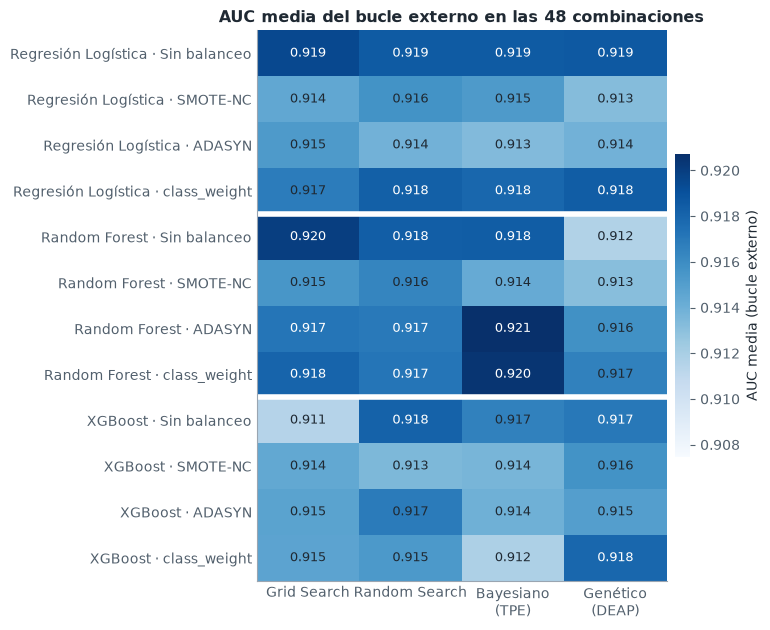

In [7]:
piv = (resumen.pivot_table(index=["modelo", "balanceo"], columns="metodo", values="auc_media")
       .reindex(index=pd.MultiIndex.from_product([config.MODELOS, config.BALANCEOS]),
                columns=config.OPTIMIZADORES))

fig, ax = plt.subplots(figsize=(7.8, 6.4))
im = ax.imshow(piv.values, cmap="Blues", aspect="auto",
               vmin=piv.values.min() - 0.004, vmax=piv.values.max())
corte = np.quantile(piv.values, 0.6)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                color="white" if v > corte else gr.TINTA)
ax.set_xticks(range(4), [N[o].replace(" (", "\n(") for o in config.OPTIMIZADORES])
ax.set_yticks(range(12), [f"{N[m]} · {N[b]}" for m, b in piv.index])
ax.tick_params(length=0)
ax.grid(False)
for y in (3.5, 7.5):
    ax.axhline(y, color="white", lw=4)
cb = plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cb.set_label("AUC media (bucle externo)")
cb.outline.set_visible(False)
ax.set_title("AUC media del bucle externo en las 48 combinaciones")
plt.tight_layout()
plt.show()

Las 48 combinaciones quedan en una franja muy estrecha: la AUC media del bucle externo va de 0,911 a 0,921, una diferencia de 0,009, mientras que la desviación estándar de **cada** combinación entre pliegues ronda 0,04. Es decir, la variación de un pliegue a otro es más de cuatro veces mayor que la distancia entre la mejor y la peor combinación. La mejor es Random Forest con ADASYN y optimización bayesiana (0,921 ± 0,039), casi empatada con otros dos Random Forest (`class_weight` con TPE y sin balanceo con Grid Search, ambos 0,920) y con la regresión logística sin balanceo (0,919), que con un modelo lineal y 15 segundos de cómputo queda a 0,001 del primer puesto.

Dos patrones se repiten en el mapa: la regresión logística es casi insensible al optimizador (su espacio tiene solo dos dimensiones y todos los métodos llegan a la misma región de $C$), y el algoritmo genético ocupa la última columna en las cuatro filas de Random Forest (en XGBoost el peor método cambia de una fila a otra). La sección 2.4 explica por qué. Si estas diferencias son reales o ruido de muestreo es lo que decide la sección 2.11.

### Efecto del balanceo

Para aislar el efecto del balanceo se promedian, para cada modelo, los 40 resultados externos de cada técnica (4 optimizadores × 10 pliegues). La AUC no depende del umbral, así que el balanceo debería moverla poco; donde sí debe notarse es en el recall y la precision con el umbral de 0,5, porque reequilibrar las clases desplaza las probabilidades hacia GBM.

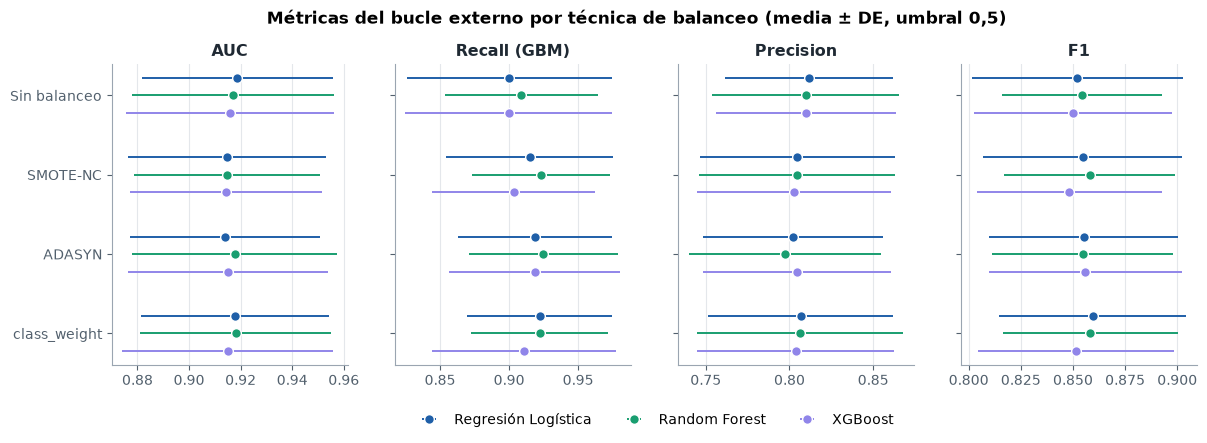

Regresión Logística               Random Forest                \
                             auc recall     f1           auc recall     f1   
Sin balanceo               0.919  0.900  0.852         0.917  0.909  0.854   
SMOTE-NC                   0.915  0.915  0.855         0.915  0.923  0.858   
ADASYN                     0.914  0.918  0.855         0.918  0.925  0.855   
class_weight               0.918  0.922  0.859         0.918  0.922  0.858   

             XGBoost                
                 auc recall     f1  
Sin balanceo   0.916  0.900  0.850  
SMOTE-NC       0.914  0.903  0.848  
ADASYN         0.915  0.919  0.856  
class_weight   0.915  0.911  0.852

In [8]:
bal = (pliegues.groupby(["modelo", "balanceo"])[["auc", "recall", "precision", "f1", "brier"]]
       .agg(["mean", "std"]))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.9), sharey=True)
for ax, (met, titulo) in zip(axes, [("auc", "AUC"), ("recall", "Recall (GBM)"),
                                    ("precision", "Precision"), ("f1", "F1")]):
    for k, m in enumerate(config.MODELOS):
        medias = [bal.loc[(m, b), (met, "mean")] for b in config.BALANCEOS]
        de = [bal.loc[(m, b), (met, "std")] for b in config.BALANCEOS]
        y = np.arange(4) + (k - 1) * 0.22
        ax.errorbar(medias, y, xerr=de, fmt="o", color=config.COLOR_MODELO[m], ms=7,
                    elinewidth=1.4, capsize=0, label=N[m], markeredgecolor="white")
    ax.set_title(titulo)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(4), [N[b] for b in config.BALANCEOS])
axes[0].invert_yaxis()
axes[0].legend(loc="upper center", bbox_to_anchor=(2.3, -0.12), ncol=3)
fig.suptitle("Métricas del bucle externo por técnica de balanceo (media ± DE, umbral 0,5)",
             fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

tabla_bal = pd.DataFrame({
    (N[m], met): [f"{bal.loc[(m, b), (met, 'mean')]:.3f}" for b in config.BALANCEOS]
    for m in config.MODELOS for met in ["auc", "recall", "f1"]
}, index=[N[b] for b in config.BALANCEOS])
tabla_bal

Como se esperaba, el balanceo casi no mueve la AUC (todas las técnicas quedan dentro de ±0,005 para cada modelo), porque reequilibrar las clases cambia la escala de las probabilidades pero apenas el orden de los pacientes. Su efecto aparece con el umbral de 0,5: las tres técnicas suben el recall de GBM hasta 2,2 puntos (de 0,900 a 0,922 en la logística, de 0,900 a 0,919 en XGBoost) a cambio de una precision algo menor, y el F1 queda prácticamente igual.

`class_weight` consigue ese desplazamiento sin crear pacientes, cuesta lo mismo que no balancear y es la técnica con mejor F1 en la regresión logística. SMOTE-NC y ADASYN dan resultados parecidos, pero multiplican el costo: el sobremuestreo de SMOTE-NC sobre 22 variables nominales es la operación más lenta de todo el pipeline (sección 2.6). Con un desbalance de 1,38:1, el sobremuestreo sintético no aporta nada que la ponderación no consiga, y ADASYN añade además valores binarios intermedios que no corresponden a ningún paciente real. La técnica de balanceo es, en este problema, una herramienta para **elegir el punto de operación** (más recall o más precision), no para mejorar la discriminación.

## 2.4 Comparación de los métodos de optimización

### Curvas de desempeño en cualquier momento (*anytime performance*)

Cada búsqueda guarda la AUC interna de cada una de sus 24 evaluaciones en el orden en que se hicieron. El máximo acumulado de esa secuencia, $\max_{s \le t} \text{AUC}_s$, es la mejor solución disponible si la búsqueda se detuviera en la evaluación $t$. Las curvas promedian las 40 búsquedas de cada modelo y optimizador (4 balanceos × 10 pliegues externos). En Grid Search el orden es el de la rejilla, de modo que su curva depende de cómo esté escrita.

Como las cuatro curvas quedan a milésimas unas de otras, se grafica la **brecha**: en cada bloque (balanceo × pliegue externo), la mejor AUC interna que encontró cualquiera de los cuatro métodos menos la mejor que lleva el método en la evaluación $t$. Escala logarítmica; más abajo es mejor.

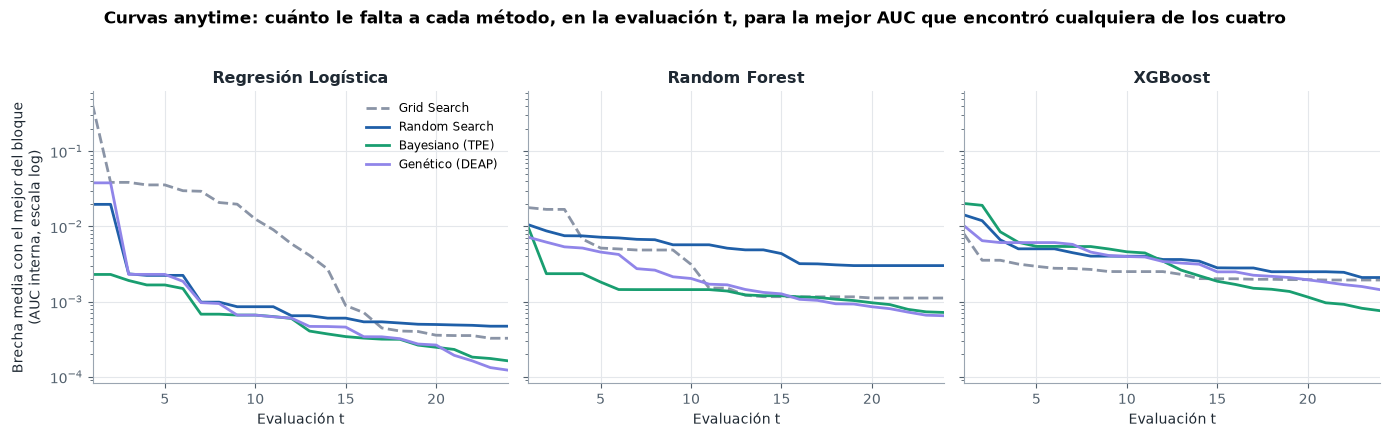

In [9]:
P = config.PRESUPUESTO

def acumulada(h):
    c = gr.mejor_acumulado(h)
    return np.pad(c, (0, max(0, P - len(c))), mode="edge")[:P]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
t = np.arange(1, P + 1)
for ax, m in zip(axes, config.MODELOS):
    curvas = {o: np.array([acumulada(h) for b in config.BALANCEOS
                           for h in historiales[exp.id_combo(m, b, o)]])
              for o in config.OPTIMIZADORES}
    # referencia de cada bloque (balanceo x pliegue): lo mejor que encontró cualquier método
    referencia = np.max([c[:, -1] for c in curvas.values()], axis=0)
    for o in config.OPTIMIZADORES:
        brecha = (referencia[:, None] - curvas[o]).mean(0)
        ax.plot(t, np.maximum(brecha, 1e-4), color=config.COLOR_OPTIMIZADOR[o], lw=2,
                ls="--" if o == "grid" else "-", label=N[o])
    ax.set_yscale("log")
    ax.set_title(N[m])
    ax.set_xlabel("Evaluación t")
    ax.set_xlim(1, P)
axes[0].set_ylabel("Brecha media con el mejor del bloque\n(AUC interna, escala log)")
axes[0].legend(loc="upper right", fontsize=8.5)
fig.suptitle("Curvas anytime: cuánto le falta a cada método, en la evaluación t, para la mejor AUC "
             "que encontró cualquiera de los cuatro", fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

### Evidencia cuantitativa de eficiencia

Comparar curvas a ojo no basta. Para cada uno de los 120 bloques (3 modelos × 4 balanceos × 10 pliegues externos) se toma como referencia la mejor AUC interna que encontró **cualquiera** de los cuatro métodos en ese bloque, y para cada método se mide:

- la mejor AUC interna tras 6, 12 y 24 evaluaciones;
- el **área bajo la curva anytime** (media de la curva en las 24 evaluaciones; premia llegar pronto);
- el **porcentaje de bloques** en que el método llega a menos de 0,001 de la referencia, y la **mediana de evaluaciones** que necesita para hacerlo;
- la AUC del bucle externo, que es lo que importa al final, y el tiempo por evaluación.

Las diferencias frente a Random Search se contrastan con la prueba de Wilcoxon pareada por bloque, con ajuste de Holm.

In [10]:
bloques = []
for m in config.MODELOS:
    for b in config.BALANCEOS:
        curvas = {o: [acumulada(h) for h in historiales[exp.id_combo(m, b, o)]]
                  for o in config.OPTIMIZADORES}
        for f in range(config.K_EXTERNO):
            referencia = max(curvas[o][f][-1] for o in config.OPTIMIZADORES)
            for o in config.OPTIMIZADORES:
                c = curvas[o][f]
                llega = c >= referencia - 0.001
                bloques.append({"modelo": m, "balanceo": b, "pliegue": f, "metodo": o,
                                "t6": c[5], "t12": c[11], "t24": c[23], "area": c.mean(),
                                "llega": llega.any(),
                                "evals": int(np.argmax(llega)) + 1 if llega.any() else np.nan})
bloques = pd.DataFrame(bloques).merge(
    pliegues[["modelo", "balanceo", "metodo", "pliegue", "auc", "auc_interna", "t_por_eval",
              "t_busqueda"]],
    on=["modelo", "balanceo", "metodo", "pliegue"])

eficiencia = bloques.groupby("metodo").agg(
    t6=("t6", "mean"), t12=("t12", "mean"), t24=("t24", "mean"), area=("area", "mean"),
    llega=("llega", "mean"), evals=("evals", "median"), auc_externa=("auc", "mean"),
    auc_interna=("auc_interna", "mean"),
    t_eval=("t_por_eval", "mean"), t_total=("t_busqueda", "sum")).reindex(config.OPTIMIZADORES)

# Wilcoxon pareado frente a Random Search, por bloque
pruebas = []
ref = bloques[bloques.metodo == "random"].set_index(["modelo", "balanceo", "pliegue"])
for o in ["grid", "bayesiano", "genetico"]:
    otro = bloques[bloques.metodo == o].set_index(["modelo", "balanceo", "pliegue"])
    for col in ["t12", "t24", "area", "auc"]:
        d = otro[col] - ref.loc[otro.index, col]
        pruebas.append({"metodo": o, "medida": col, "dif_media": d.mean(),
                        "p": stats.wilcoxon(d, zero_method="zsplit").pvalue})
pruebas = pd.DataFrame(pruebas)
pruebas["p_holm"] = ev.holm(pruebas["p"])

tabla_ef = pd.DataFrame({
    "AUC interna t=6": eficiencia["t6"].map("{:.4f}".format),
    "t=12": eficiencia["t12"].map("{:.4f}".format),
    "t=24": eficiencia["t24"].map("{:.4f}".format),
    "Área anytime": eficiencia["area"].map("{:.4f}".format),
    "% bloques al mejor": (eficiencia["llega"] * 100).map("{:.0f} %".format),
    "Evals. al mejor (mediana)": eficiencia["evals"],
    "AUC externa": eficiencia["auc_externa"].map("{:.4f}".format),
    "Optimismo (interna − externa)": (eficiencia["auc_interna"] - eficiencia["auc_externa"]).map("{:+.4f}".format),
    "s / evaluación": eficiencia["t_eval"].map("{:.2f}".format),
    "Búsqueda total (min, suma de pliegues)": (eficiencia["t_total"] / 60).map("{:.1f}".format),
}).rename(index=N).rename_axis(None)
display(tabla_ef)

tabla_w = pruebas.assign(Método=pruebas.metodo.map(N)).pivot(index="Método", columns="medida")
tabla_w = pd.DataFrame({
    f"{c}": [f"{tabla_w.loc[i, ('dif_media', c)]:+.4f} (p_Holm = {tabla_w.loc[i, ('p_holm', c)]:.3f})"
             for i in tabla_w.index]
    for c in ["t12", "t24", "area", "auc"]}, index=tabla_w.index)
tabla_w.columns = ["Δ AUC interna t=12", "Δ AUC interna t=24", "Δ área anytime", "Δ AUC externa"]
print("Diferencia media frente a Random Search (Wilcoxon pareado, 120 bloques, ajuste de Holm)")
tabla_w

,AUC interna t=6,t=12,t=24,Área anytime,% bloques al mejor,Evals. al mejor (mediana),AUC externa,Optimismo (interna − externa),s / evaluación,"Búsqueda total (min, suma de pliegues)"
Grid Search,0.9055,0.9148,0.9169,0.9060,62 %,13.0,0.9160,+0.0009,1.31,62.7
Random Search,0.9133,0.9149,0.9162,0.9140,42 %,8.0,0.9166,-0.0004,1.47,70.5
Bayesiano (TPE),0.9153,0.9163,0.9175,0.9157,78 %,7.0,0.9162,+0.0013,1.38,66.2
Genético (DEAP),0.9140,0.9162,0.9173,0.9147,78 %,9.0,0.9156,+0.0018,1.32,63.5


Diferencia media frente a Random Search (Wilcoxon pareado, 120 bloques, ajuste de Holm)


,Δ AUC interna t=12,Δ AUC interna t=24,Δ área anytime,Δ AUC externa
Método,,,,
Bayesiano (TPE),+0.0013 (p_Holm = 0.000),+0.0013 (p_Holm = 0.000),+0.0017 (p_Holm = 0.000),-0.0003 (p_Holm = 1.000)
Genético (DEAP),+0.0012 (p_Holm = 0.000),+0.0011 (p_Holm = 0.000),+0.0006 (p_Holm = 0.219),-0.0010 (p_Holm = 1.000)
Grid Search,-0.0002 (p_Holm = 1.000),+0.0007 (p_Holm = 0.000),-0.0081 (p_Holm = 0.025),-0.0006 (p_Holm = 1.000)


Con las 24 evaluaciones completas los cuatro métodos llegan a una AUC interna casi idéntica (0,9162–0,9175), pero no llegan igual de rápido:

- **TPE es el más eficiente por unidad de presupuesto.** Tras 6 evaluaciones ya tiene una AUC interna de 0,9153, más que Random Search tras 12 (0,9149); tiene el área *anytime* más alta, alcanza la mejor solución del bloque en el 78 % de los casos y necesita una mediana de 7 evaluaciones para hacerlo. Las diferencias frente a Random Search en $t = 12$, $t = 24$ y en el área son pequeñas (+0,001) pero sistemáticas: aparecen en casi todos los bloques y son significativas tras el ajuste de Holm ($p < 0{,}001$). Las primeras ocho evaluaciones de TPE son aleatorias; a partir de ahí el sustituto concentra la búsqueda en la región buena, como muestra el historial de abajo.
- **Grid Search** depende del orden de la rejilla: empieza por la esquina de mayor regularización (en la logística, $C = 0{,}001$ con L1, que anula todos los coeficientes y da AUC 0,5), de ahí su área *anytime* significativamente menor (−0,008). Al final llega a una AUC interna similar porque, con 24 puntos en 2–4 dimensiones, la rejilla cubre bien los espacios de la logística y de Random Forest.
- **Random Search** es la línea base: avanza de forma regular pero es el que menos veces alcanza el mejor del bloque (42 %), sobre todo en Random Forest.
- **El algoritmo genético encuentra soluciones internas tan buenas como TPE** (78 % de bloques al mejor), pero tiene el mayor **optimismo**: su AUC interna supera a la externa en 0,0018, frente a 0,0013 en TPE y menos de 0,001 en los demás. Termina con la AUC externa más baja de los cuatro (0,9156), aunque la diferencia con Random Search (−0,0010) no es significativa ($p_\text{Holm} = 1{,}000$).

La tendencia del último punto tiene una explicación en el bucle interno: el genético explota agresivamente las configuraciones que mejor puntúan en **esos tres pliegues internos concretos**, y con unos 200 pacientes por pliegue esa ventaja es en buena parte ruido. Una búsqueda más eficiente sobre una métrica ruidosa tiende a sobreajustar la métrica; aquí el efecto es pequeño. El costo por evaluación es prácticamente el mismo en los cuatro métodos (1,3–1,5 s): la lógica de TPE y del genético es despreciable frente al ajuste de los modelos, así que su ventaja en calidad por evaluación es también ventaja por segundo.

### Historial de una búsqueda bayesiana

El gráfico de historial (*history plot*) de Optuna muestra cada evaluación y el mejor valor acumulado. Se compara con Random Search en el mismo bloque (XGBoost sin balanceo, primer pliegue externo): las 8 primeras evaluaciones de TPE son aleatorias, y a partir de ahí el sustituto concentra la búsqueda en la región buena.

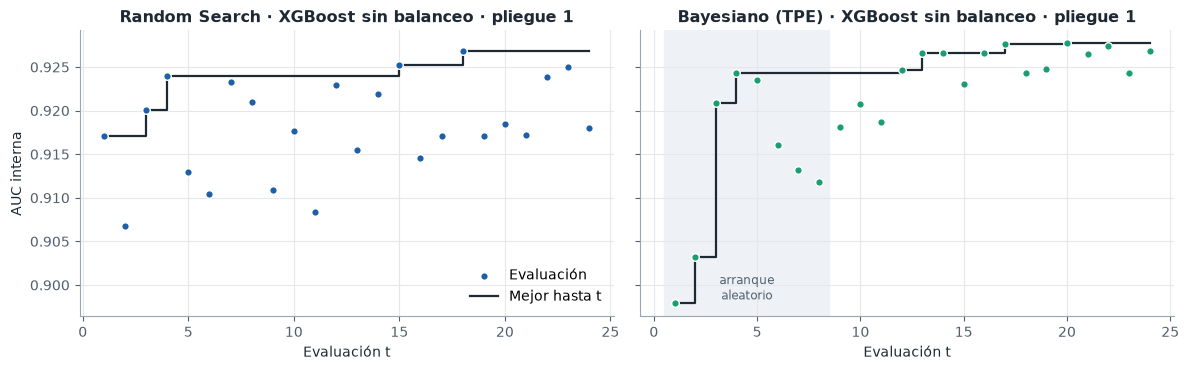

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, o in zip(axes, ["random", "bayesiano"]):
    h = np.array(historiales[exp.id_combo("xgboost", "ninguno", o)][0])
    t = np.arange(1, len(h) + 1)
    ax.scatter(t, h, s=30, color=config.COLOR_OPTIMIZADOR[o], edgecolor="white", zorder=3,
               label="Evaluación")
    ax.step(t, gr.mejor_acumulado(h), where="post", color=gr.TINTA, lw=1.6,
            label="Mejor hasta t")
    if o == "bayesiano":
        ax.axvspan(0.5, 8.5, color="#eef2f7", zorder=0)
        ax.text(4.5, h.min(), "arranque\naleatorio", ha="center", va="bottom", fontsize=8.5,
                color=gr.TINTA_2)
    ax.set_title(f"{N[o]} · XGBoost sin balanceo · pliegue 1")
    ax.set_xlabel("Evaluación t")
axes[0].set_ylabel("AUC interna")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

### Convergencia y diversidad del algoritmo genético

En cada generación se registra la mejor aptitud, la aptitud media de la población y su diversidad genética. Una diversidad que cae a cero mientras la media alcanza al mejor indica convergencia prematura: la población se ha vuelto una copia del mismo individuo y el cruce deja de explorar.

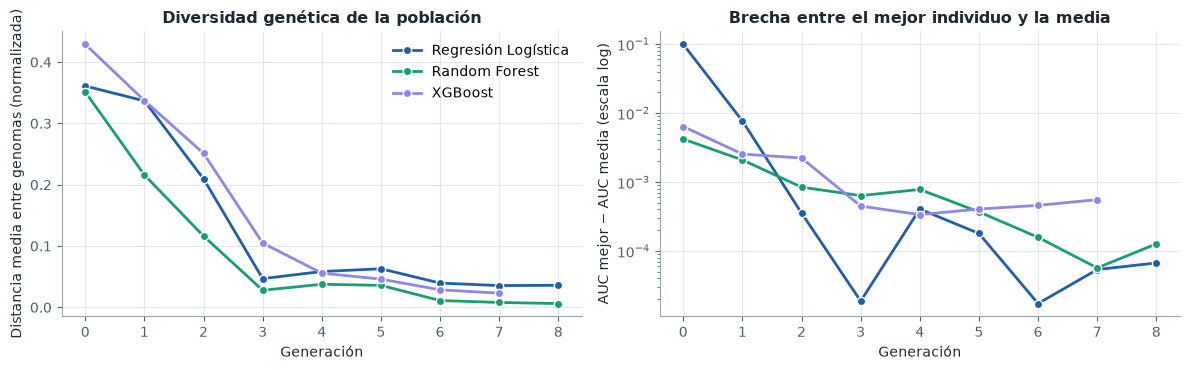

,Generaciones necesarias (media),Generaciones (máx.),Diversidad inicial,Diversidad final,"% corridas con diversidad final < 0,05"
modelo,,,,,
Regresión Logística,11.0,22,0.361,0.040,62.0
Random Forest,7.8,14,0.351,0.018,85.0
XGBoost,5.7,7,0.429,0.053,45.0


In [12]:
gen = pd.DataFrame([{"modelo": c.split("|")[0], "corrida": f"{c}|{k}", **g}
                    for c, por_pliegue in geneticos.items()
                    for k, registros in enumerate(por_pliegue) for g in registros])
G_MAX = 8   # generaciones que se grafican (más allá solo quedan unas pocas corridas)
gen_m = (gen[gen.generacion <= G_MAX]
         .groupby(["modelo", "generacion"])[["mejor", "media", "diversidad"]].mean().reset_index())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for m in config.MODELOS:
    d = gen_m[gen_m.modelo == m]
    axes[0].plot(d.generacion, d.diversidad, "-o", color=config.COLOR_MODELO[m], lw=2,
                 label=N[m], markeredgecolor="white")
    axes[1].plot(d.generacion, np.maximum(d.mejor - d.media, 1e-5), "-o", color=config.COLOR_MODELO[m], lw=2,
                 label=N[m], markeredgecolor="white")
axes[0].set_title("Diversidad genética de la población")
axes[0].set_ylabel("Distancia media entre genomas (normalizada)")
axes[1].set_title("Brecha entre el mejor individuo y la media")
axes[1].set_ylabel("AUC mejor − AUC media (escala log)")
axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("Generación")
    ax.set_xticks(range(G_MAX + 1))
axes[0].legend()
plt.tight_layout()
plt.show()

por_corrida = gen.groupby(["modelo", "corrida"]).agg(
    generaciones=("generacion", "max"), evaluaciones=("evaluaciones", "max"),
    div_inicial=("diversidad", "first"), div_final=("diversidad", "last"))
por_corrida["colapso"] = por_corrida.div_final < 0.05
pd.DataFrame({
    "Generaciones necesarias (media)": por_corrida.groupby("modelo").generaciones.mean().round(1),
    "Generaciones (máx.)": por_corrida.groupby("modelo").generaciones.max(),
    "Diversidad inicial": por_corrida.groupby("modelo").div_inicial.mean().round(3),
    "Diversidad final": por_corrida.groupby("modelo").div_final.mean().round(3),
    "% corridas con diversidad final < 0,05": (por_corrida.groupby("modelo").colapso.mean() * 100).round(0),
}).reindex(config.MODELOS).rename(index=N)

La diversidad cae de ≈ 0,4 a menos de 0,1 en tres generaciones, y en ese mismo tiempo la brecha entre el mejor individuo y la media de la población se cierra a menos de 0,001 de AUC: la población converge muy pronto. En el 45–85 % de las corridas la diversidad final queda por debajo de 0,05, lo que es **convergencia prematura**. Una consecuencia visible es que la población empieza a producir hijos que se decodifican a configuraciones ya evaluadas; como el caché no les cobra presupuesto, el algoritmo necesita en promedio entre 6 y 11 generaciones (hasta 22 en la logística, cuyo espacio de dos dimensiones se agota rápido) para completar las 24 evaluaciones nuevas.

Con μ = 6 la población es demasiado pequeña para mantener diversidad con selección por torneo y esquema elitista $(\mu + \lambda)$; la presión selectiva es alta para el tamaño del problema. Una población mayor (μ ≥ 15), una mutación más fuerte o un esquema $(\mu, \lambda)$ no elitista mantendrían más exploración, pero con 24 evaluaciones una población grande no alcanzaría a evolucionar. En presupuestos tan pequeños, el genético está en desventaja estructural frente a un método basado en un modelo sustituto.

### Optimización multi-fidelidad: *Successive Halving*

Como técnica adicional de eficiencia se probó *Successive Halving* sobre XGBoost (sin balanceo). La **fidelidad** es el número de árboles: es la medida natural del costo de un modelo de *boosting* y, para tasas de aprendizaje razonables, el orden de las configuraciones con pocos árboles predice bien su orden con muchos. Se parte de 81 candidatos con 15 árboles y en cada ronda se conserva el mejor tercio con el triple de árboles (**factor de reducción 3**): 81 → 27 → 9 → 3 candidatos con 15 → 45 → 135 → 405 árboles. Cada ronda consume el mismo número de árboles (1 215 por pliegue), unos 4 860 en total, comparable a los ≈ 5 400 de un Random Search de 24 configuraciones con un número medio de 225 árboles. Ambos se evalúan con la misma validación anidada de 10 × 3 pliegues.

In [13]:
def comparar_halving():
    dist = modelos.distribuciones_random("xgboost")
    dist.pop("modelo__n_estimators")
    externo = StratifiedKFold(config.K_EXTERNO, shuffle=True, random_state=config.SEED)
    filas = []
    for metodo in ["Random Search", "Successive Halving"]:
        for i, (tr, va) in enumerate(externo.split(X_train, y_train)):
            interno = StratifiedKFold(config.K_INTERNO, shuffle=True, random_state=config.SEED)
            pipe = modelos.construir_pipeline("xgboost", "ninguno")
            if metodo == "Random Search":
                busqueda = RandomizedSearchCV(
                    pipe, {**dist, "modelo__n_estimators": randint(50, 401)}, n_iter=P,
                    scoring="roc_auc", cv=interno, random_state=config.SEED, n_jobs=2)
            else:
                busqueda = HalvingRandomSearchCV(
                    pipe, dist, resource="modelo__n_estimators", min_resources=15,
                    max_resources=405, factor=3, n_candidates=81, scoring="roc_auc",
                    cv=interno, random_state=config.SEED, n_jobs=2)
            t0 = time.perf_counter()
            busqueda.fit(X_train.iloc[tr], y_train.iloc[tr])
            t = time.perf_counter() - t0
            proba = busqueda.best_estimator_.predict_proba(X_train.iloc[va])[:, 1]
            arboles = (sum(busqueda.n_candidates_[r] * busqueda.n_resources_[r]
                           for r in range(busqueda.n_iterations_))
                       if metodo != "Random Search"
                       else int(np.sum(busqueda.cv_results_["param_modelo__n_estimators"])))
            filas.append({"metodo": metodo, "pliegue": i, "t": t,
                          "auc_interna": busqueda.best_score_,
                          "auc_externa": roc_auc_score(y_train.iloc[va], proba),
                          "candidatos": len(busqueda.cv_results_["params"]),
                          "arboles": arboles})
    return pd.DataFrame(filas)

halving = en_cache("halving", comparar_halving, RECALCULAR)
h = halving.groupby("metodo").agg(
    candidatos=("candidatos", "mean"), arboles=("arboles", "mean"), t=("t", "mean"),
    auc_interna=("auc_interna", "mean"), auc_externa=("auc_externa", "mean"),
    auc_externa_de=("auc_externa", "std"))
d = halving.pivot(index="pliegue", columns="metodo", values="auc_externa")
p_h = stats.wilcoxon(d["Successive Halving"] - d["Random Search"]).pvalue
display(pd.DataFrame({
    "Configuraciones evaluadas": h.candidatos.astype(int),
    "Árboles ajustados por fold interno": h.arboles.round(0).astype(int),
    "Tiempo por búsqueda (s)": h.t.round(2),
    "AUC interna": h.auc_interna.round(4),
    "AUC externa (media ± DE)": [f"{a:.4f} ± {s:.4f}" for a, s in zip(h.auc_externa, h.auc_externa_de)],
}))
print(f"Wilcoxon pareado sobre la AUC externa (10 pliegues): p = {p_h:.3f}")

,Configuraciones evaluadas,Árboles ajustados por fold interno,Tiempo por búsqueda (s),AUC interna,AUC externa (media ± DE)
metodo,,,,,
Random Search,24,5288,16.88,0.9167,0.9181 ± 0.0422
Successive Halving,120,4860,35.72,0.9120,0.9131 ± 0.0444


Wilcoxon pareado sobre la AUC externa (10 pliegues): p = 0.129


*Successive Halving* **no mejoró** a Random Search en este problema: evaluó cinco veces más configuraciones con un número parecido de árboles (4 860 frente a 5 288), pero tardó el doble por búsqueda (35,7 s frente a 16,9 s) y obtuvo una AUC externa algo menor (0,913 frente a 0,918; diferencia no significativa, $p = 0{,}129$). Hay dos razones. La primera es de costo: con 400 pacientes por pliegue interno un árbol cuesta microsegundos, de modo que el tiempo lo dominan los costos fijos de cada ajuste (preparar los datos, crear el modelo, la validación cruzada), y Halving hace 120 ajustes por pliegue en lugar de 24; ahorrar árboles no ahorra tiempo. La segunda es de fidelidad: con *learning rates* bajos, 15 árboles son un modelo muy incompleto y su ranking predice mal el de 405, así que la primera ronda descarta configuraciones que habrían sido buenas. Los métodos multi-fidelidad rinden cuando cada evaluación completa es cara (redes neuronales, datos de millones de filas); aquí no lo es.

## 2.5 Selección de los modelos finales

Para cada familia se elige la combinación de balanceo y optimizador con mayor AUC media en el bucle externo. Después, ese optimizador se ejecuta **una vez más sobre los 671 pacientes de entrenamiento completos** para fijar los hiperparámetros definitivos, y el pipeline resultante se ajusta con todos ellos. La AUC del bucle externo es la estimación de generalización del *procedimiento* (balanceo + optimizador + modelo); el modelo final es el que ese procedimiento produce con todos los datos disponibles.

In [14]:
seleccion = (resumen.loc[resumen.groupby("modelo")["auc_media"].idxmax()]
             .set_index("modelo").loc[config.MODELOS])

def entrenar_finales():
    finales = {}
    for m, fila in seleccion.iterrows():
        res = opt.buscar(fila["metodo"], m, fila["balanceo"], X_train, y_train)
        pipe = modelos.construir_pipeline(m, fila["balanceo"], **res.mejores_params)
        pipe.fit(X_train, y_train)
        finales[m] = {"pipeline": pipe, "params": res.mejores_params,
                      "auc_interna": res.mejor_score, "balanceo": fila["balanceo"],
                      "metodo": fila["metodo"]}
    return finales

finales = en_cache("modelos_finales", entrenar_finales, RECALCULAR)

pd.DataFrame({
    "Balanceo": [N[f["balanceo"]] for f in finales.values()],
    "Optimizador": [N[f["metodo"]] for f in finales.values()],
    "AUC externa (10 pliegues)": [f"{seleccion.loc[m, 'auc_media']:.4f} ± {seleccion.loc[m, 'auc_de']:.4f}"
                                  for m in finales],
    "Hiperparámetros finales": [", ".join(f"{k} = {_fmt(round(v, 4) if isinstance(v, float) else v)}"
                                          for k, v in f["params"].items())
                                for f in finales.values()],
}, index=[N[m] for m in finales])

,Balanceo,Optimizador,AUC externa (10 pliegues),Hiperparámetros finales
Regresión Logística,Sin balanceo,Grid Search,0.9194 ± 0.0384,"C = 0.5337, penalty = l1"
Random Forest,ADASYN,Bayesiano (TPE),0.9207 ± 0.0392,"max_depth = 10, min_samples_leaf = 4, max_feat..."
XGBoost,Sin balanceo,Random Search,0.9181 ± 0.0422,"colsample_bytree = 0.8515, learning_rate = 0.0..."


## 2.6 Optimización computacional

### Complejidad algorítmica

Notación: $n$ pacientes, $p$ predictoras, $T$ árboles, $d$ profundidad máxima, $I$ iteraciones del *solver*, $B$ número de *bins* del histograma (256 por defecto en XGBoost).

| Modelo | Entrenamiento | Inferencia (por paciente) | Optimización aplicada |
|---|---|---|---|
| Regresión logística (`liblinear`) | $O(I \cdot n \cdot p)$ | $O(p)$ | *Solver* de descenso por coordenadas, lineal en $n$ y $p$ por iteración |
| Random Forest | $O(T \cdot m \cdot n \log n)$, con $m$ = variables por división | $O(T \cdot d)$ | Submuestreo de variables ($m < p$), paralelización entre árboles y pliegues |
| XGBoost exacto | $O(T \cdot d \cdot p \cdot n \log n)$ | $O(T \cdot d)$ | — |
| XGBoost `hist` | $O(n \cdot p)$ una vez + $O(T \cdot d \cdot (n \cdot p + B \cdot p))$ | $O(T \cdot d)$ | Histogramas en lugar de ordenar, *early stopping* |

La teoría se contrasta con el tiempo medido variando $n$ y $p$ de forma controlada: se remuestrean pacientes del entrenamiento (con reemplazo) para obtener $n$ entre 200 y 25 600, y se añaden columnas binarias de ruido para llevar $p$ de 23 a 736. La pendiente de $\log t$ frente a $\log n$ (o $\log p$) en el tramo de los cuatro tamaños mayores es el exponente empírico de escalamiento: si el entrenamiento es $O(n)$, la pendiente debería acercarse a 1; si es $O(n \log n)$, a algo ligeramente mayor que 1. Con pocos datos domina el costo fijo de cada ajuste y la pendiente es menor.

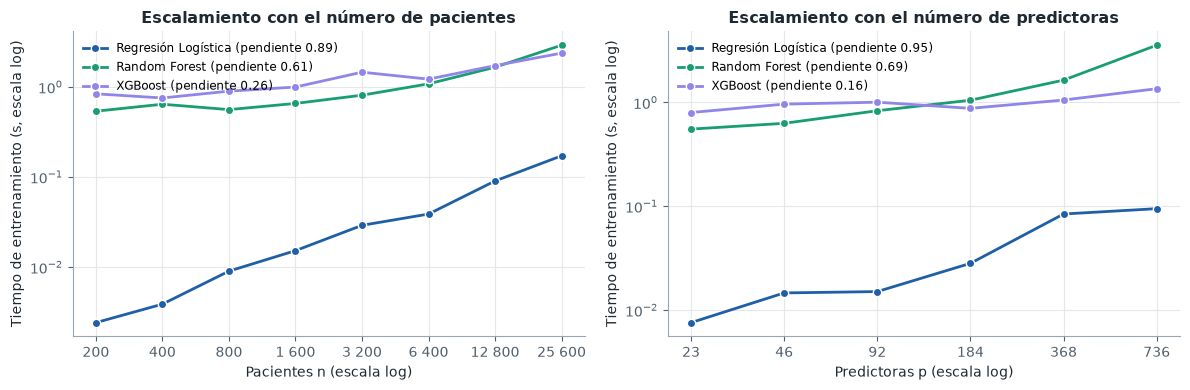

In [15]:
def _tiempo(f, rep=3):
    ts = []
    for _ in range(rep):
        t0 = time.perf_counter()
        f()
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

def escalamiento():
    rng = np.random.default_rng(config.SEED)
    Xa, ya = X_train.to_numpy(float), y_train.to_numpy()
    filas = []
    for m, f in finales.items():
        est = lambda: modelos.estimador(m, "ninguno", **f["params"])
        for n in [200, 400, 800, 1600, 3200, 6400, 12800, 25600]:
            idx = rng.integers(0, len(ya), n)
            filas.append({"modelo": m, "eje": "n", "valor": n,
                          "t": _tiempo(lambda: est().fit(Xa[idx], ya[idx]))})
        for p in [23, 46, 92, 184, 368, 736]:
            ruido = rng.integers(0, 2, (len(ya), p - 23))
            Xp = np.hstack([Xa, ruido])
            filas.append({"modelo": m, "eje": "p", "valor": p,
                          "t": _tiempo(lambda: est().fit(Xp, ya))})
    return pd.DataFrame(filas)

esc = en_cache("escalamiento", escalamiento, RECALCULAR)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pendientes = {}
for ax, eje, etiqueta in [(axes[0], "n", "Pacientes n"), (axes[1], "p", "Predictoras p")]:
    for m in config.MODELOS:
        d = esc[(esc.modelo == m) & (esc.eje == eje)]
        # La pendiente se estima en el tramo asintótico (los 4 tamaños mayores): con
        # pocos datos domina el costo fijo (crear los árboles, validar la entrada).
        b = np.polyfit(np.log(d.valor.iloc[-4:]), np.log(d.t.iloc[-4:]), 1)[0]
        pendientes[(m, eje)] = b
        ax.plot(d.valor, d.t, "-o", color=config.COLOR_MODELO[m], lw=2,
                markeredgecolor="white", label=f"{N[m]} (pendiente {b:.2f})")
    ax.set_xscale("log")
    ax.set_yscale("log")
    valores = sorted(esc.loc[esc.eje == eje, "valor"].unique())
    ax.set_xticks(valores, [f"{v:,}".replace(",", " ") for v in valores])
    ax.minorticks_off()
    ax.set_xlabel(f"{etiqueta} (escala log)")
    ax.set_ylabel("Tiempo de entrenamiento (s, escala log)")
    ax.legend(fontsize=8.5, loc="upper left")
axes[0].set_title("Escalamiento con el número de pacientes")
axes[1].set_title("Escalamiento con el número de predictoras")
plt.tight_layout()
plt.show()

Las pendientes empíricas son coherentes con la teoría, una vez se tiene en cuenta el costo fijo:

- **Regresión logística:** pendientes de 0,89 en $n$ y 0,95 en $p$, cercanas a la linealidad, como predice $O(I \cdot n \cdot p)$ del descenso por coordenadas.
- **XGBoost (`hist`):** pendientes de 0,26 en $n$ y 0,16 en $p$, las más bajas de los tres. Con árboles de profundidad 2 cada ronda es muy barata, de modo que en estos tamaños el tiempo lo domina el costo fijo de las 317 rondas y no la construcción de histogramas ($O(n \cdot p)$ por nivel); en $p$ la pendiente es aún menor porque `colsample_bytree = 0,85` solo usa parte de las columnas en cada árbol.
- **Random Forest:** pendientes de 0,61 en $n$ y 0,69 en $p$. Con `max_depth = 10` el costo por árbol es $O(m \cdot n \cdot d)$ (lineal en $n$, sin el factor $\log n$ de los árboles sin límite), pero los 200 árboles tienen un costo fijo de ≈ 0,55 s que con $n \le 3\,200$ domina el total. Restando ese costo fijo, el tiempo crece prácticamente en proporción a $n$.

En el tamaño real del problema ($n = 671$, $p = 23$) los tres modelos se entrenan en menos de 1 s; ninguno está cerca de ser un cuello de botella, y lo que encarece el experimento es el número de ajustes (34 560), no el costo de cada uno.

### XGBoost: histogramas frente a método exacto, y *early stopping*

El método `exact` ordena los valores de cada variable en cada nodo; `hist` los agrupa una sola vez en $B$ *bins* y busca divisiones sobre los histogramas. Con variables binarias casi no hay valores que agrupar, así que la ganancia de `hist` aparece sobre todo al crecer $n$ y $p$. El *early stopping* detiene el *boosting* cuando la pérdida en un conjunto de validación independiente (20 % del pliegue de entrenamiento, estratificado) deja de mejorar durante 30 rondas.

In [16]:
def xgb_metodos():
    f = finales["xgboost"]
    rng = np.random.default_rng(config.SEED)
    Xa, ya = X_train.to_numpy(float), y_train.to_numpy()
    filas = []
    for n, p in [(671, 23), (6400, 23), (6400, 184)]:
        idx = rng.integers(0, len(ya), n) if n != len(ya) else np.arange(len(ya))
        Xn = np.hstack([Xa[idx], rng.integers(0, 2, (n, p - 23))]) if p > 23 else Xa[idx]
        for tm in ["exact", "hist"]:
            est = lambda: modelos.estimador("xgboost", "ninguno", tree_method=tm, **f["params"])
            filas.append({"n": n, "p": p, "metodo": tm,
                          "t": _tiempo(lambda: est().fit(Xn, ya[idx]))})
    return pd.DataFrame(filas)

def early_stopping():
    f = finales["xgboost"]
    cv = StratifiedKFold(5, shuffle=True, random_state=config.SEED)
    filas = []
    for i, (tr, va) in enumerate(cv.split(X_train, y_train)):
        Xtr, ytr = X_train.iloc[tr], y_train.iloc[tr]
        for variante in ["Fijo (hiperparámetros finales)", "Early stopping (máx. 2000)"]:
            pipe = modelos.construir_pipeline("xgboost", f["balanceo"], **f["params"])
            t0 = time.perf_counter()
            if variante.startswith("Early"):
                a, b = next(StratifiedKFold(5, shuffle=True, random_state=config.SEED).split(Xtr, ytr))
                pipe.set_params(modelo__n_estimators=2000, modelo__early_stopping_rounds=30)
                escala = clone(pipe.named_steps["escala"]).fit(Xtr.iloc[a])
                pipe.fit(Xtr.iloc[a], ytr.iloc[a],
                         modelo__eval_set=[(escala.transform(Xtr.iloc[b]), ytr.iloc[b])],
                         modelo__verbose=False)
                arboles = pipe.named_steps["modelo"].best_iteration + 1
            else:
                pipe.fit(Xtr, ytr)
                arboles = f["params"].get("n_estimators", 200)
            t = time.perf_counter() - t0
            filas.append({"variante": variante, "pliegue": i, "t": t, "arboles": arboles,
                          "auc": roc_auc_score(y_train.iloc[va],
                                               pipe.predict_proba(X_train.iloc[va])[:, 1])})
    return pd.DataFrame(filas)

xm = en_cache("xgb_metodos", xgb_metodos, RECALCULAR)
tabla_xm = xm.pivot_table(index=["n", "p"], columns="metodo", values="t")
tabla_xm["Aceleración (exact / hist)"] = (tabla_xm["exact"] / tabla_xm["hist"]).round(2)
display(tabla_xm.rename(columns={"exact": "exact (s)", "hist": "hist (s)"}).round(3))

es = en_cache("early_stopping", early_stopping, RECALCULAR)
es.groupby("variante").agg(arboles=("arboles", "mean"), tiempo_s=("t", "mean"),
                           auc_media=("auc", "mean"), auc_de=("auc", "std")).round(4)

metodo    exact (s)  hist (s)  Aceleración (exact / hist)
n    p                                                   
671  23       0.936     0.770                        1.22
6400 23       1.666     1.008                        1.65
     184      5.920     1.832                        3.23

,arboles,tiempo_s,auc_media,auc_de
variante,,,,
Early stopping (máx. 2000),202.2,0.8286,0.9155,0.0190
Fijo (hiperparámetros finales),317.0,0.7466,0.9184,0.0209


El método `hist` es más rápido en los tres escenarios, y la ganancia crece con el tamaño de los datos, como predice la complejidad: 1,2 veces en los datos reales, 1,7 veces con 6 400 pacientes y 3,2 veces con 6 400 pacientes y 184 predictoras. La ganancia es mayor cuando crece el número de predictoras, porque el método exacto paga el ordenamiento de cada variable en cada nodo, mientras que `hist` la resume una sola vez en histogramas.

El *early stopping* no compensa aquí: el criterio de parada se detuvo en promedio en 202 árboles en lugar de los 317 elegidos, tardó algo más (0,83 s frente a 0,75 s) y obtuvo una AUC algo menor (0,916 frente a 0,918), porque entrena con el 80 % del pliegue (el 20 % restante se reserva para decidir cuándo parar). El número de árboles ya está optimizado como hiperparámetro dentro de la validación anidada, de modo que el *early stopping* solo duplica esa decisión con menos datos. Sería útil si se fijara un *learning rate* y se dejara libre el número de árboles.

### Paralelización y perfilamiento

El bucle externo es vergonzosamente paralelo: cada pliegue busca y evalúa de forma independiente. `optimizacion.validacion_anidada` lo reparte con `joblib` (*backend* `loky`, procesos separados, que evita el bloqueo global del intérprete), y los modelos internos usan un solo hilo para no sobresuscribir los núcleos. Se mide el tiempo de reloj de una validación anidada completa con 1 y 2 procesos. No hay GPU disponible en el equipo de ejecución, por lo que no se evaluó `device='cuda'` en XGBoost; con 671 pacientes la transferencia de datos a la GPU costaría más que el propio entrenamiento.

In [17]:
def paralelo():
    filas = []
    for nj in [1, 2]:
        t0 = time.perf_counter()
        opt.validacion_anidada("random", "xgboost", "ninguno", X_train, y_train, n_jobs=nj)
        filas.append({"procesos": nj, "t": time.perf_counter() - t0})
    return pd.DataFrame(filas)

par = en_cache("paralelo", paralelo, RECALCULAR)
par["Aceleración"] = (par.t.iloc[0] / par.t).round(2)
par["Eficiencia"] = (par["Aceleración"] / par.procesos).round(2)
par.rename(columns={"procesos": "Procesos", "t": "Tiempo (s)"}).round(1).set_index("Procesos")

,Tiempo (s),Aceleración,Eficiencia
Procesos,,,
1,323.8,1.0,1.0
2,227.8,1.4,0.7


El perfilamiento con `cProfile` de una búsqueda completa (Random Search, regresión logística con SMOTE-NC, la combinación más lenta en relación con el costo de su modelo) muestra dónde se va el tiempo antes de optimizar nada. Además se descompone el ajuste de cada pipeline final en sus tres pasos.

In [18]:
perfil = cProfile.Profile()
perfil.enable()
opt.buscar("random", "logistica", "smote", X_train, y_train)
perfil.disable()
salida = io.StringIO()
pstats.Stats(perfil, stream=salida).sort_stats("tottime").print_stats(8)
print("\n".join(l for l in salida.getvalue().splitlines()[:30] if l.strip()))

         10074177 function calls (10005293 primitive calls) in 21.348 seconds
   Ordered by: internal time
   List reduced from 1458 to 8 due to restriction <8>
   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
     1584    7.545    0.005   11.443    0.007 C:\Users\joshu\miniconda3\envs\gliomas-modelado\Lib\site-packages\scipy\sparse\_data.py:248(_argminmax_axis)
   821568    1.384    0.000    3.622    0.000 C:\Users\joshu\miniconda3\envs\gliomas-modelado\Lib\site-packages\numpy\_core\fromnumeric.py:1259(argmax)
   821568    1.239    0.000    1.239    0.000 {method 'argmax' of 'numpy.ndarray' objects}
   832162    0.736    0.000    2.415    0.000 C:\Users\joshu\miniconda3\envs\gliomas-modelado\Lib\site-packages\numpy\_core\fromnumeric.py:48(_wrapfunc)
992314/991810    0.366    0.000    0.398    0.000 {built-in method builtins.getattr}
   180664    0.344    0.000    0.344    0.000 C:\Users\joshu\miniconda3\envs\gliomas-modelado\Lib\inspect.py:1832(_shadowed_dict)
 

In [19]:
def desglose(m, f):
    pipe = modelos.construir_pipeline(m, f["balanceo"], **f["params"])
    t0 = time.perf_counter(); Xe = pipe.named_steps["escala"].fit_transform(X_train)
    t1 = time.perf_counter()
    s = pipe.named_steps["balanceo"]
    Xb, yb = (Xe, y_train) if s == "passthrough" else s.fit_resample(Xe, y_train)
    t2 = time.perf_counter(); pipe.named_steps["modelo"].fit(Xb, yb); t3 = time.perf_counter()
    return {"Escalado (ms)": (t1 - t0) * 1e3, "Balanceo (ms)": (t2 - t1) * 1e3,
            "Modelo (ms)": (t3 - t2) * 1e3}

pd.DataFrame({N[m] + f" · {N[f['balanceo']]}": desglose(m, f) for m, f in finales.items()}).T.round(1)

,Escalado (ms),Balanceo (ms),Modelo (ms)
Regresión Logística · Sin balanceo,10.8,0.0,4.5
Random Forest · ADASYN,11.1,19.3,518.3
XGBoost · Sin balanceo,8.5,0.0,574.4


La paralelización del bucle externo con dos procesos reduce el tiempo de una validación anidada completa de 324 s a 228 s, una aceleración de 1,42 y una eficiencia de 0,71, lejos del ideal de 2: los pliegues son independientes, pero los dos procesos compiten por la memoria y la caché, y crear los procesos con `loky` y repartirles los datos tiene un costo. Con más núcleos la aceleración seguiría creciendo, aunque por debajo de la línea ideal, hasta 10 procesos (uno por pliegue externo).

El perfilamiento muestra que, en la combinación regresión logística + SMOTE-NC, la mayor parte del tiempo no está en el modelo sino en el balanceo: las funciones que más tiempo propio consumen son `_argminmax_axis` de `scipy.sparse` y `numpy.argmax`, llamadas cientos de miles de veces por SMOTE-NC para decidir, en cada paciente sintético, el valor más frecuente de cada una de las 22 variables nominales entre sus vecinos. Es la razón por la que las combinaciones con SMOTE-NC tardan entre cuatro y seis veces más que las demás en la regresión logística (≈ 57 s frente a 9–14 s). En los pipelines finales, en cambio, el ajuste del modelo domina: 518 ms en Random Forest frente a 19 ms de ADASYN y 11 ms de escalado.

### Modelo estándar frente a optimizado

La versión **estándar** es cada modelo con los valores por defecto de su librería (logística L2 con $C = 1$ y *solver* `lbfgs`; Random Forest con 100 árboles sin límite de profundidad; XGBoost con 100 árboles, profundidad 6, *learning rate* 0,3 y método exacto). La **optimizada** es el pipeline final de la sección 2.5. El desempeño se compara con una validación cruzada de 10 pliegues sobre el entrenamiento, para no gastar el conjunto de prueba; la memoria es el pico de asignaciones de Python durante el ajuste (`tracemalloc`; no incluye la memoria interna de C++ de XGBoost) y el tamaño del modelo serializado.

In [20]:
from imblearn.pipeline import Pipeline as PipelineImb
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

def estandar(m):
    base = {"logistica": LogisticRegression(max_iter=1000),
            "random_forest": RandomForestClassifier(random_state=config.SEED),
            "xgboost": xgb.XGBClassifier(tree_method="exact", random_state=config.SEED)}[m]
    pipe = modelos.construir_pipeline(m, "ninguno")
    return PipelineImb(pipe.steps[:-1] + [("modelo", base)])

def comparar_estandar():
    cv = StratifiedKFold(10, shuffle=True, random_state=config.SEED)
    filas = []
    for m, f in finales.items():
        for version, pipe in [("Estándar", estandar(m)), ("Optimizado", clone(f["pipeline"]))]:
            t_fit = _tiempo(lambda: clone(pipe).fit(X_train, y_train))
            ajustado = clone(pipe).fit(X_train, y_train)
            t_pred = _tiempo(lambda: ajustado.predict_proba(X_test), rep=10)
            tracemalloc.start()
            clone(pipe).fit(X_train, y_train)
            pico = tracemalloc.get_traced_memory()[1]
            tracemalloc.stop()
            auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
            filas.append({"Modelo": N[m], "Versión": version,
                          "Entrenamiento (ms)": t_fit * 1e3,
                          "Inferencia 168 pac. (ms)": t_pred * 1e3,
                          "Memoria pico (MB)": pico / 2**20,
                          "Tamaño modelo (KB)": len(pickle.dumps(ajustado)) / 1024,
                          "AUC CV": f"{auc.mean():.4f} ± {auc.std(ddof=1):.4f}",
                          "_auc": auc.mean()})
    return pd.DataFrame(filas)

est = en_cache("estandar_vs_optimizado", comparar_estandar, RECALCULAR)
complejidad = {"Regresión Logística": "O(I·n·p)", "Random Forest": "O(T·m·n log n)",
               "XGBoost": "exact: O(T·d·p·n log n) · hist: O(T·d·n·p)"}
est.insert(2, "Complejidad", est["Modelo"].map(complejidad))
est["Δ AUC vs estándar"] = est.groupby("Modelo")["_auc"].transform(lambda s: s - s.iloc[0]).map("{:+.4f}".format)
est.drop(columns="_auc").set_index(["Modelo", "Versión"]).round(2)

Complejidad  \
Modelo              Versión                                                  
Regresión Logística Estándar                                      O(I·n·p)   
                    Optimizado                                    O(I·n·p)   
Random Forest       Estándar                                O(T·m·n log n)   
                    Optimizado                              O(T·m·n log n)   
XGBoost             Estándar    exact: O(T·d·p·n log n) · hist: O(T·d·n·p)   
                    Optimizado  exact: O(T·d·p·n log n) · hist: O(T·d·n·p)   

                                Entrenamiento (ms)  Inferencia 168 pac. (ms)  \
Modelo              Versión                                                    
Regresión Logística Estándar                 19.23                      5.58   
                    Optimizado               13.44                      5.16   
Random Forest       Estándar                278.54                     23.30   
                    Optimizado              555.94                     38.43   
XGBoost             Estándar                251.75                      9.54   
                    Optimizado              545.84                      7.71   

                                Memoria pico (MB)  Tamaño modelo (KB)  \
Modelo              Versión                                             
Regresión Logística Estándar                 0.31                2.61   
                    Optimizado               0.30                2.60   
Random Forest       Estándar                 0.39             2171.35   
                    Optimizado               0.75             1074.19   
XGBoost             Estándar                 0.29              171.84   
                    Optimizado               0.28              283.73   

                                         AUC CV Δ AUC vs estándar  
Modelo              Versión                                        
Regresión Logística Estándar    0.9203 ± 0.0386           +0.0000  
                    Optimizado  0.9177 ± 0.0403           -0.0026  
Random Forest       Estándar    0.9057 ± 0.0390           +0.0000  
                    Optimizado  0.9202 ± 0.0397           +0.0146  
XGBoost             Estándar    0.8990 ± 0.0336           +0.0000  
                    Optimizado  0.9197 ± 0.0407           +0.0206

La optimización mejora claramente a los dos modelos de árboles: +0,015 de AUC en Random Forest (los árboles sin límite de profundidad y con hojas de un paciente sobreajustan) y +0,020 en XGBoost, cuyos valores por defecto (profundidad 6, *learning rate* 0,3) son demasiado agresivos para 671 pacientes. El XGBoost optimizado tarda más que el estándar (546 ms frente a 252 ms): aunque usa árboles de profundidad 2 y el método `hist`, ajusta 317 árboles en lugar de 100. El Random Forest optimizado tarda más (200 árboles frente a 100) pero ocupa la mitad de memoria serializada, porque sus árboles son más pequeños.

En la regresión logística la versión optimizada (L1, $C = 0{,}53$) queda **ligeramente por debajo** de la estándar (L2, $C = 1$): −0,003, una diferencia muy inferior a la desviación entre pliegues (≈ 0,04). Es un recordatorio de que la optimización selecciona con una estimación ruidosa: con 23 predictoras y 671 pacientes la regresión logística apenas necesita regularización, y cualquier valor de $C$ razonable da el mismo resultado. Todos los modelos ocupan menos de 1 MB de memoria Python durante el ajuste y predicen los 168 pacientes de prueba en menos de 40 ms.

## 2.7 Evaluación final en el conjunto de prueba

Los tres pipelines finales se aplican, por primera y única vez, a los 168 pacientes de prueba. Las predicciones usan el umbral de 0,5 sobre la probabilidad de GBM; el intervalo de confianza de la AUC es bootstrap BCa (2 000 réplicas remuestreando pacientes).

In [21]:
proba_test = {m: f["pipeline"].predict_proba(X_test)[:, 1] for m, f in finales.items()}
yt = y_test.to_numpy()

filas = []
for m in config.MODELOS:
    p = proba_test[m]
    met = opt.metricas(yt, p)
    lo, hi = ev.ic_bootstrap(roc_auc_score, yt, p)
    tn, fp, fn, tp = confusion_matrix(yt, p >= 0.5).ravel()
    filas.append({"Modelo": N[m], "Accuracy": met["accuracy"], "Precision": met["precision"],
                  "Recall (GBM)": met["recall"], "Especificidad": tn / (tn + fp),
                  "F1": met["f1"], "AUC": met["auc"], "IC 95 % AUC": f"[{lo:.3f}, {hi:.3f}]",
                  "Brier": met["brier"], "FN": fn, "FP": fp})
metricas_test = pd.DataFrame(filas).set_index("Modelo")
metricas_test.round(3)

,Accuracy,Precision,Recall (GBM),Especificidad,F1,AUC,IC 95 % AUC,Brier,FN,FP
Modelo,,,,,,,,,,
Regresión Logística,0.875,0.810,0.914,0.847,0.859,0.923,"[0.875, 0.957]",0.102,6,15
Random Forest,0.857,0.780,0.914,0.816,0.842,0.926,"[0.878, 0.957]",0.108,6,18
XGBoost,0.863,0.805,0.886,0.847,0.844,0.930,"[0.888, 0.962]",0.101,8,15


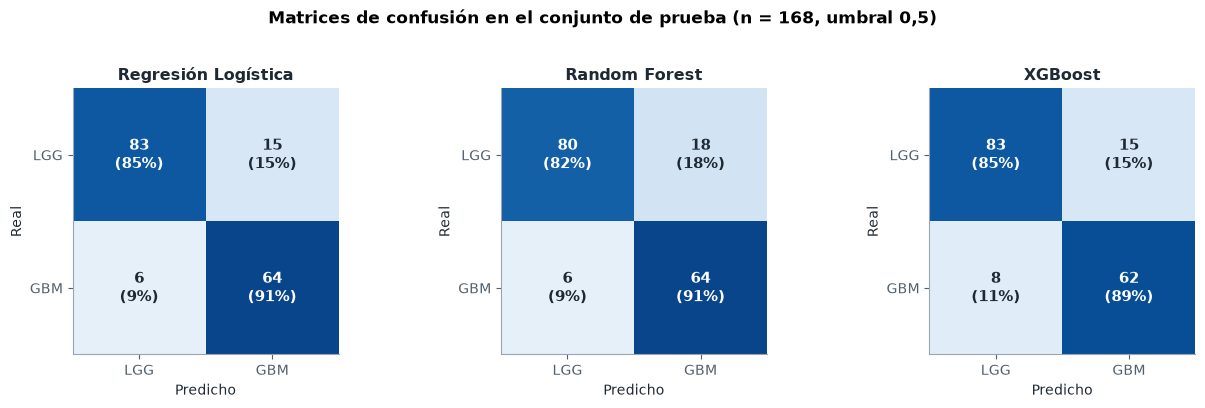

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, m in zip(axes, config.MODELOS):
    cm = confusion_matrix(yt, proba_test[m] >= 0.5)
    pct = cm / cm.sum(1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({pct[i, j]:.0%})", ha="center", va="center",
                    fontsize=11, fontweight="bold", color="white" if pct[i, j] > 0.5 else gr.TINTA)
    ax.set_xticks([0, 1], ["LGG", "GBM"])
    ax.set_yticks([0, 1], ["LGG", "GBM"])
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
    ax.grid(False)
    ax.set_title(N[m])
fig.suptitle("Matrices de confusión en el conjunto de prueba (n = 168, umbral 0,5)",
             fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

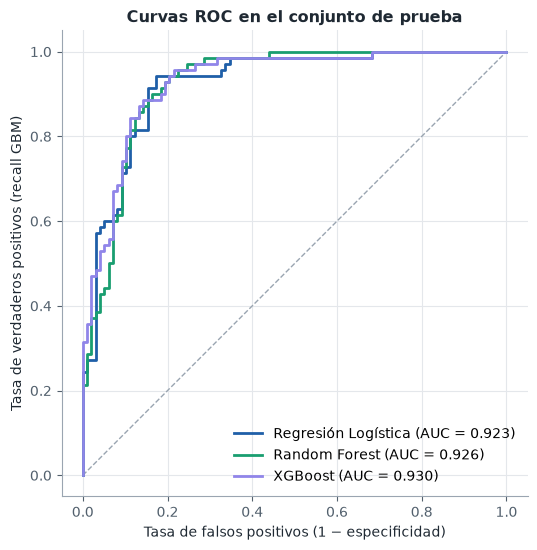

In [23]:
fig, ax = plt.subplots(figsize=(6.2, 5.6))
ax.plot([0, 1], [0, 1], color="#9aa5b1", lw=1, ls="--")
for m in config.MODELOS:
    fpr, tpr, _ = roc_curve(yt, proba_test[m])
    ax.plot(fpr, tpr, color=config.COLOR_MODELO[m], lw=2,
            label=f"{N[m]} (AUC = {metricas_test.loc[N[m], 'AUC']:.3f})")
ax.set_xlabel("Tasa de falsos positivos (1 − especificidad)")
ax.set_ylabel("Tasa de verdaderos positivos (recall GBM)")
ax.set_title("Curvas ROC en el conjunto de prueba")
ax.legend(loc="lower right")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

En el conjunto de prueba los tres modelos son prácticamente equivalentes: AUC de 0,923 (logística), 0,926 (Random Forest) y 0,930 (XGBoost), con intervalos de confianza de unos ±0,04 que se solapan casi por completo. Las AUC en prueba son incluso algo mayores que las del bucle externo (0,918–0,921), una señal de que la validación anidada no sobreestimó el desempeño.

Con el umbral de 0,5 los modelos detectan entre el 89 % y el 91 % de los glioblastomas (6 a 8 falsos negativos de 70) y clasifican correctamente entre el 82 % y el 85 % de los LGG. La regresión logística tiene la mejor accuracy (0,875) y, junto con XGBoost, el menor número de falsos positivos (15). Los errores no son simétricos: hay unas dos veces más falsos positivos que falsos negativos (15–18 frente a 6–8), lo cual es deseable en este contexto clínico, porque un LGG marcado como sospechoso de GBM lleva a pruebas adicionales, mientras que un GBM clasificado como LGG retrasa un tratamiento urgente. Si se quisiera aún más sensibilidad, bastaría con bajar el umbral, pero el costo crece rápido: según las curvas ROC, llevar el recall al 95 % exige aceptar entre un 21 % (XGBoost) y un 33 % (logística) de falsos positivos.

## 2.8 Calibración de probabilidades

Una AUC alta solo garantiza que el modelo **ordena** bien a los pacientes; no que una probabilidad de 0,8 signifique que 8 de cada 10 de esos pacientes tienen GBM. Si el modelo se usara para apoyar decisiones clínicas, la probabilidad misma importa. La calibración se evalúa con:

- el **diagrama de confiabilidad** (probabilidad predicha media frente a frecuencia observada de GBM en *bins* de igual ancho);
- el **Brier score**, error cuadrático medio entre probabilidad y desenlace, que combina calibración y discriminación;
- el **ECE** (*Expected Calibration Error*), promedio ponderado de la distancia entre confianza y frecuencia observada.

Se usan dos fuentes: las probabilidades fuera de pliegue del bucle externo sobre los 671 pacientes de entrenamiento (más puntos por *bin*) y las del conjunto de prueba.

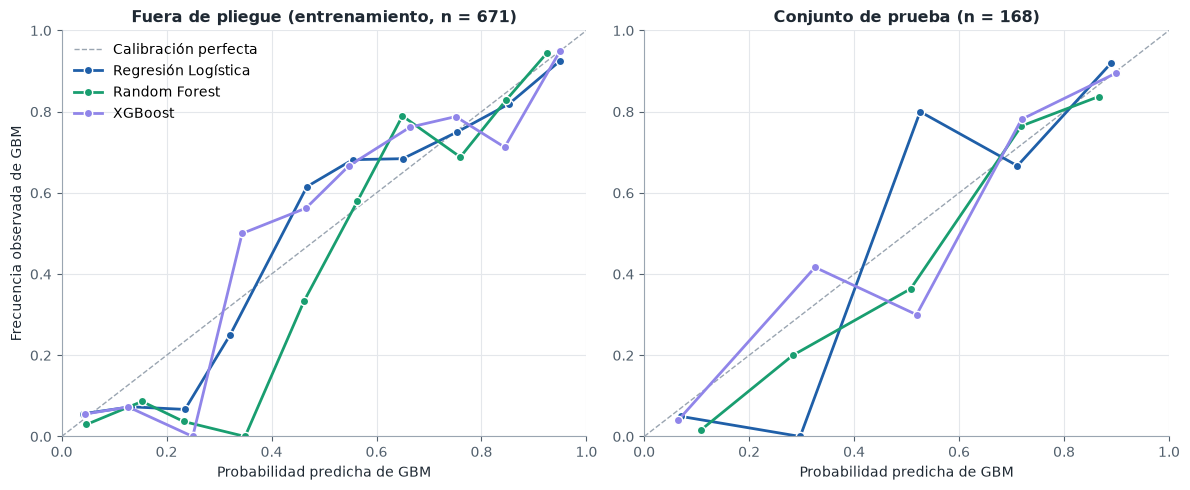

,Brier OOF,ECE OOF,Brier test,ECE test
Regresión Logística,0.1031,0.0318,0.1021,0.0497
Random Forest,0.1080,0.0571,0.1077,0.0692
XGBoost,0.1058,0.0466,0.1011,0.0435


In [24]:
oof_sel = {m: oof[exp.id_combo(m, f["balanceo"], f["metodo"])].to_numpy() for m, f in finales.items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (fuente, y_, probas, bins) in zip(axes, [
        ("Fuera de pliegue (entrenamiento, n = 671)", y_train.to_numpy(), oof_sel, 10),
        ("Conjunto de prueba (n = 168)", yt, proba_test, 5)]):
    ax.plot([0, 1], [0, 1], color="#9aa5b1", lw=1, ls="--", label="Calibración perfecta")
    for m in config.MODELOS:
        gr.confiabilidad(ax, ev.curva_confiabilidad(y_, probas[m], bins),
                         config.COLOR_MODELO[m], N[m])
    ax.set_title(fuente)
    ax.set_xlabel("Probabilidad predicha de GBM")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
axes[0].set_ylabel("Frecuencia observada de GBM")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "Brier OOF": [opt.metricas(y_train, oof_sel[m])["brier"] for m in config.MODELOS],
    "ECE OOF": [ev.ece(y_train, oof_sel[m]) for m in config.MODELOS],
    "Brier test": [metricas_test.loc[N[m], "Brier"] for m in config.MODELOS],
    "ECE test": [ev.ece(yt, proba_test[m], 5) for m in config.MODELOS],
}, index=[N[m] for m in config.MODELOS]).round(4)

### Recalibración

Se prueban las dos técnicas clásicas, ajustadas con validación cruzada de 5 pliegues **sobre el entrenamiento** (`CalibratedClassifierCV`): el **escalado de Platt** (una sigmoide sobre la salida del modelo, paramétrico y estable con pocos datos) y la **regresión isotónica** (una función monótona escalonada, más flexible pero con riesgo de sobreajuste con pocos pacientes por *bin*). Su efecto se mide en el conjunto de prueba.

In [25]:
def recalibrar():
    filas = []
    for m, f in finales.items():
        filas.append({"Modelo": N[m], "Método": "Sin recalibrar",
                      **{k: v for k, v in opt.metricas(yt, proba_test[m]).items() if k in ("auc", "brier")},
                      "ece": ev.ece(yt, proba_test[m], 5)})
        for metodo, nombre in [("sigmoid", "Platt"), ("isotonic", "Isotónica")]:
            cal = CalibratedClassifierCV(clone(f["pipeline"]), method=metodo,
                                         cv=StratifiedKFold(5, shuffle=True, random_state=config.SEED))
            cal.fit(X_train, y_train)
            p = cal.predict_proba(X_test)[:, 1]
            filas.append({"Modelo": N[m], "Método": nombre, "auc": roc_auc_score(yt, p),
                          "brier": opt.metricas(yt, p)["brier"], "ece": ev.ece(yt, p, 5)})
    return pd.DataFrame(filas)

recal = en_cache("recalibracion", recalibrar, RECALCULAR)
recal.rename(columns={"auc": "AUC test", "brier": "Brier test", "ece": "ECE test"}) \
     .set_index(["Modelo", "Método"]).round(4)

AUC test  Brier test  ECE test
Modelo              Método                                        
Regresión Logística Sin recalibrar    0.9235      0.1021    0.0497
                    Platt             0.9230      0.1023    0.0347
                    Isotónica         0.9214      0.1014    0.0179
Random Forest       Sin recalibrar    0.9258      0.1077    0.0692
                    Platt             0.9281      0.1024    0.0519
                    Isotónica         0.9270      0.1040    0.0313
XGBoost             Sin recalibrar    0.9302      0.1011    0.0435
                    Platt             0.9268      0.1031    0.0462
                    Isotónica         0.9224      0.1035    0.0477

La regresión logística y XGBoost están razonablemente bien calibrados (ECE fuera de pliegue de 0,032 y 0,047); sus curvas siguen la diagonal salvo en la zona intermedia (0,3–0,5), donde hay pocos pacientes y la frecuencia observada oscila alrededor de la predicha. Random Forest es el peor calibrado (ECE 0,057 fuera de pliegue, 0,069 en prueba): entre 0,3 y 0,5 predice probabilidades de GBM claramente mayores que la frecuencia observada. Es el efecto combinado de dos cosas conocidas: el promedio de árboles comprime las probabilidades hacia el centro y ADASYN, que se eligió para este modelo, desplaza las probabilidades hacia la clase minoritaria al entrenar con más GBM sintéticos de los que hay en la población.

La recalibración reduce el ECE de la logística y de Random Forest casi sin tocar la AUC: la regresión isotónica lleva el ECE de Random Forest de 0,069 a 0,031 y el de la logística de 0,050 a 0,018. En XGBoost no ayuda: con los dos métodos el ECE de prueba sube un poco (de 0,044 a 0,046 con Platt y a 0,048 con la isotónica), y la isotónica le resta además 0,008 de AUC, porque `CalibratedClassifierCV` promedia cinco calibradores ajustados en pliegues distintos y el resultado no conserva exactamente el orden de los pacientes. El Brier score casi no cambia, porque está dominado por la discriminación, que es la misma. Con solo 168 pacientes de prueba repartidos en cinco *bins* estas cifras tienen bastante incertidumbre; la conclusión robusta es que **si se usan las probabilidades de Random Forest, conviene recalibrarlas**.

## 2.9 Interpretabilidad: SHAP y LIME

### Valores de Shapley

Los valores SHAP reparten la predicción de cada paciente entre sus variables según el valor de Shapley de la teoría de juegos cooperativos: la contribución de una variable es su aporte marginal promedio sobre todos los órdenes posibles en que las variables pueden "entrar" al modelo. Es la única atribución que cumple a la vez **eficiencia** (las contribuciones suman la predicción menos el valor base), **simetría** (dos variables que aportan lo mismo reciben lo mismo) y **aditividad**, además de dar contribución cero a una variable que no influye.

Para XGBoost se calculan con el algoritmo **TreeSHAP** exacto que implementa la propia librería (`pred_contribs=True`, el mismo que usa `shap.TreeExplainer`), en la escala del log-odds de GBM. Para la regresión logística los valores SHAP tienen forma cerrada: con variables tratadas como independientes, la contribución de la variable $j$ es $\beta_j (x_j - \bar{x}_j)$ en esa misma escala.

Mejor familia según la AUC del bucle externo: Random Forest


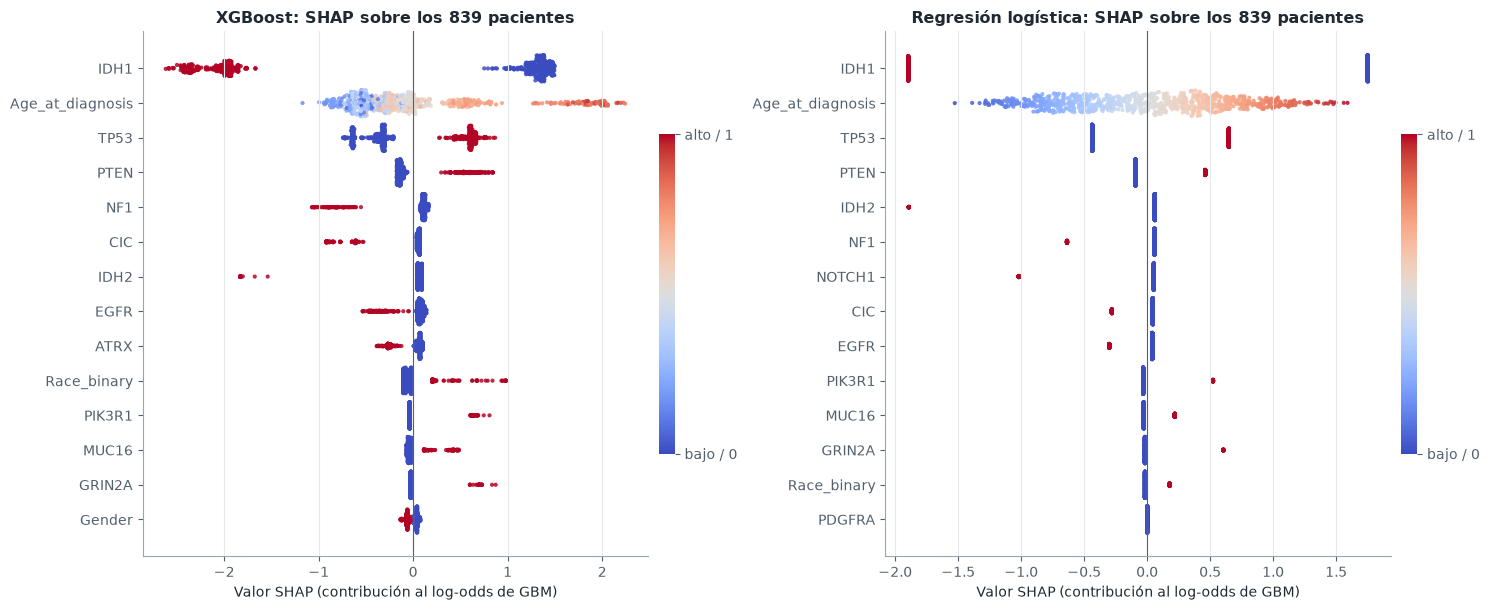

Importancia global: % del total de |SHAP| medio


,XGBoost,Regresión Logística
IDH1,42.3,49.3
Age_at_diagnosis,14.0,14.9
TP53,12.4,14.2
PTEN,5.4,4.2
NF1,4.2,2.8
CIC,3.6,2.0
IDH2,2.9,3.0
EGFR,2.9,2.0
ATRX,2.8,0.0
Race_binary,2.2,0.9


In [26]:
NOMBRES_VAR = config.PREDICTORAS
X_todos = pd.concat([X_train, X_test]).reset_index(drop=True)

def shap_xgb(pipe, X):
    Xt = pipe.named_steps["escala"].transform(X)
    contrib = pipe.named_steps["modelo"].get_booster().predict(xgb.DMatrix(Xt), pred_contribs=True)
    return contrib[:, :-1], float(contrib[0, -1])

def shap_logistica(pipe, X, X_fondo):
    esc_ = pipe.named_steps["escala"]
    beta = pipe.named_steps["modelo"].coef_[0]
    media = esc_.transform(X_fondo).mean(0)
    valores = (esc_.transform(X) - media) * beta
    return valores, float(pipe.named_steps["modelo"].intercept_[0] + beta @ media)

mejor = seleccion["auc_media"].idxmax()
print(f"Mejor familia según la AUC del bucle externo: {N[mejor]}")

sv_xgb, base_xgb = shap_xgb(finales["xgboost"]["pipeline"], X_todos)
sv_rl, base_rl = shap_logistica(finales["logistica"]["pipeline"], X_todos, X_train)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
gr.beeswarm(sv_xgb, X_todos, NOMBRES_VAR, ax=axes[0], max_vars=14,
            titulo="XGBoost: SHAP sobre los 839 pacientes")
gr.beeswarm(sv_rl, X_todos, NOMBRES_VAR, ax=axes[1], max_vars=14,
            titulo="Regresión logística: SHAP sobre los 839 pacientes")
plt.tight_layout()
plt.show()

importancia = pd.DataFrame({
    "XGBoost": np.abs(sv_xgb).mean(0), "Regresión Logística": np.abs(sv_rl).mean(0)},
    index=NOMBRES_VAR)
importancia = importancia.div(importancia.sum()).mul(100).sort_values("XGBoost", ascending=False)
print("Importancia global: % del total de |SHAP| medio")
importancia.head(10).round(1)

Los dos modelos, construidos con supuestos opuestos, cuentan la misma historia: **`IDH1` explica por sí solo casi la mitad de la contribución total** (42–49 %), seguido de la edad al diagnóstico (14–15 %), `TP53` (12–14 %) y `PTEN` (4–5 %). Estas cuatro variables reúnen entre el 74 % y el 83 % de la importancia. El sentido de los efectos principales coincide con el EDA: la mutación de `IDH1` empuja con fuerza hacia LGG (valores SHAP de −2 en log-odds), la edad avanzada hacia GBM de forma aproximadamente monótona, y la mutación de `PTEN` hacia GBM; `CIC`, `NF1` e `IDH2` mutados empujan hacia LGG.

Hay tres diferencias con el análisis univariado del EDA que muestran lo que aporta un modelo multivariante:

- **`TP53` sube al tercer lugar**, aunque su asociación marginal con `Grade` era moderada. Su efecto es condicional: una vez se sabe si hay mutación de `IDH1`, la mutación de `TP53` aumenta la probabilidad de GBM. Una explicación biológica plausible, que el modelo no puede confirmar, es que entre los gliomas con `IDH1` mutado `TP53` distingue el linaje astrocítico (que incluye los astrocitomas de alto grado) del oligodendroglial (asociado a `CIC` y `FUBP1`).
- **`ATRX` pierde casi todo su peso**: es la novena variable en XGBoost (2,8 %) y la regularización L1 de la logística la anula por completo (0 %). El EDA ya había mostrado su fuerte coocurrencia con `TP53` ($V = 0{,}55$) e `IDH1` ($V = 0{,}46$): su información es redundante con la de esas dos variables, y el modelo lineal con L1 se queda con una sola copia. En total, L1 anula 10 de las 23 variables: además de `ATRX`, `FUBP1` y `RB1`, todas las que el EDA había señalado sin asociación (`Gender`, `PDGFRA`, `CSMD3`, `BCOR`, `PIK3CA`, `FAT4`), más `SMARCA4`.
- **`EGFR` cambia de signo.** En el EDA la mutación de `EGFR` se asociaba con GBM (81 de los 112 pacientes mutados son GBM); en los dos modelos, en cambio, su contribución es **negativa** (SHAP medio negativo en XGBoost entre los pacientes con la mutación, coeficiente −0,34 en la logística). No es una contradicción: los GBM con `EGFR` mutado son también mayores y sin mutación de `IDH1`, y esas dos variables ya explican su grado. Una vez descontadas, tener `EGFR` mutado no añade riesgo de GBM, e incluso lo reduce ligeramente. Es la diferencia entre asociación marginal y efecto condicional.

XGBoost, además, capta efectos no lineales que la logística no puede representar: la contribución de la edad tiene escalones (se aprecian grupos separados de puntos), y la de `TP53` toma valores distintos según el resto del perfil del paciente.

### Explicaciones locales

Se explican dos pacientes del conjunto de prueba con XGBoost: uno **bien clasificado con alta confianza** y el **peor error** (el paciente con mayor diferencia entre su clase real y la probabilidad predicha). El gráfico *waterfall* parte del valor base (log-odds medio de la cohorte) y suma una a una las contribuciones hasta llegar a la predicción del paciente.

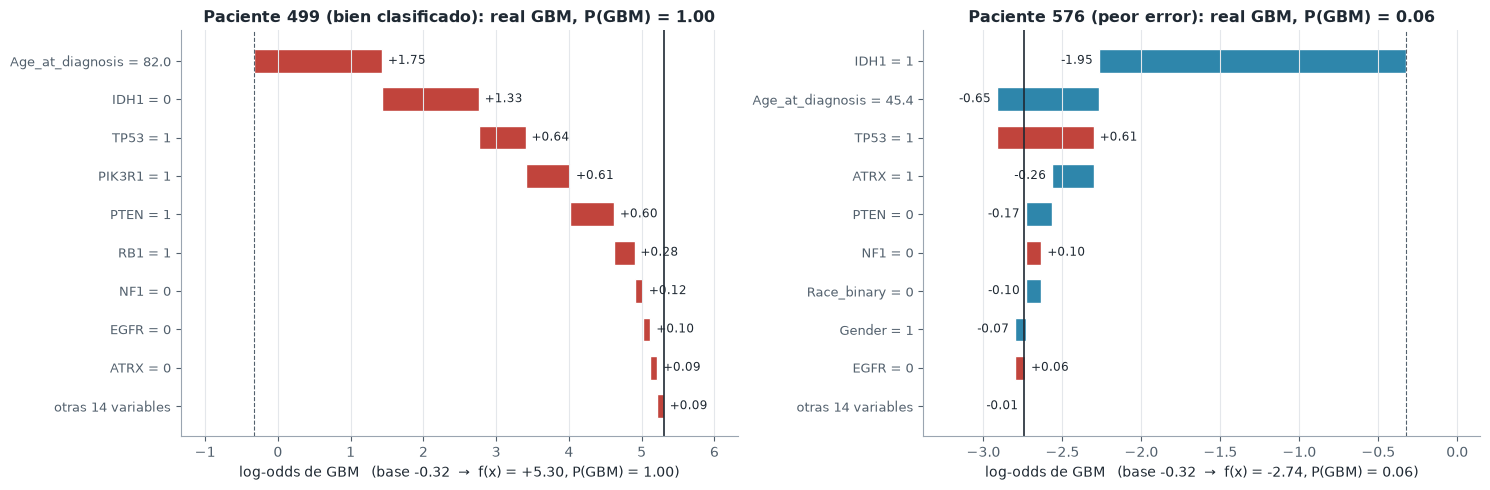

In [27]:
p_xgb = proba_test["xgboost"]
error = np.abs(yt - p_xgb)
i_bien = int(np.argmin(np.where(yt == 1, error, np.inf)))   # GBM bien clasificado con más confianza
i_mal = int(np.argmax(error))                                # peor error
sv_test, _ = shap_xgb(finales["xgboost"]["pipeline"], X_test)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, i, rotulo in [(axes[0], i_bien, "bien clasificado"), (axes[1], i_mal, "peor error")]:
    real = "GBM" if yt[i] == 1 else "LGG"
    gr.waterfall(base_xgb, sv_test[i], X_test.iloc[i].to_numpy(), NOMBRES_VAR, ax=ax,
                 titulo=f"Paciente {X_test.index[i]} ({rotulo}): real {real}, P(GBM) = {p_xgb[i]:.2f}")
plt.tight_layout()
plt.show()

**Paciente 499 (GBM, P = 0,99).** Es el perfil típico de un glioblastoma: 82 años, sin mutación de `IDH1`, con `TP53`, `PTEN` y `PIK3R1` mutados. La edad y la ausencia de `IDH1` aportan +1,75 y +1,33 en log-odds; las mutaciones de `TP53` y `PTEN` suman +1,2 adicional, y la de `PIK3R1`, +0,6. Todas las contribuciones relevantes van en la misma dirección.

**Paciente 576 (GBM, P = 0,06), el peor error.** Tiene 45 años y mutaciones en `IDH1`, `TP53` y `ATRX`. La mutación de `IDH1` (−1,95) arrastra la predicción hacia LGG; `TP53` empuja hacia GBM (+0,61) pero no alcanza a compensar, y la edad relativamente joven y la mutación de `ATRX` refuerzan la predicción de LGG. Este perfil (`IDH1` + `TP53` + `ATRX` en un adulto joven) es el de un astrocitoma con `IDH` mutado; la clasificación de la OMS de 2021 ya no llama glioblastoma a estos tumores aunque sean de grado 4, mientras que las etiquetas de TCGA siguen el criterio histológico anterior. El error del modelo no es aleatorio: corresponde a un subgrupo cuyo grado no puede deducirse del perfil mutacional disponible y que requeriría información adicional (histología, `CDKN2A/B`, 1p/19q).

### Comparación con LIME

LIME explica una predicción ajustando, alrededor del paciente, un modelo lineal ponderado sobre perturbaciones aleatorias de sus variables. Es agnóstico al modelo, pero su explicación depende de cómo se perturbe (aquí: la edad se discretiza en cuartiles y las binarias se muestrean con su frecuencia en el entrenamiento), de la anchura del núcleo de proximidad y de la semilla. Sus pesos están en la escala de la probabilidad, no del log-odds, así que se comparan **rangos y signos**, no magnitudes. Para medir la estabilidad, cada explicación se repite con 10 semillas.

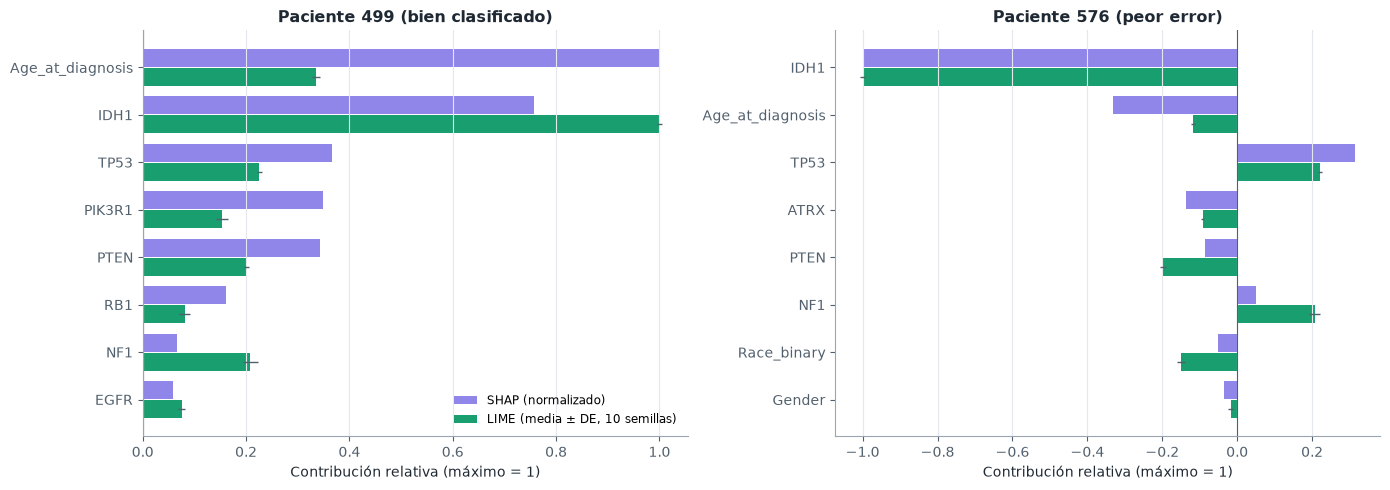

,Spearman |SHAP| vs |LIME| (23 variables),Signos coincidentes (top 8 SHAP),Top 3 SHAP,Top 3 LIME,CV medio de los pesos LIME (top 5)
Paciente,,,,,
499 (bien clasificado),0.873,100%,"Age_at_diagnosis, IDH1, TP53","IDH1, IDH2, Age_at_diagnosis",0.033
576 (peor error),0.777,100%,"IDH1, Age_at_diagnosis, TP53","IDH1, IDH2, TP53",0.038


In [28]:
explicador = LimeTabularExplainer(
    X_train.to_numpy(float), feature_names=NOMBRES_VAR, class_names=["LGG", "GBM"],
    categorical_features=list(range(1, len(NOMBRES_VAR))), discretize_continuous=True,
    mode="classification", random_state=config.SEED)
predecir = lambda A: finales["xgboost"]["pipeline"].predict_proba(pd.DataFrame(A, columns=NOMBRES_VAR))

def lime_pesos(i, semilla):
    explicador.random_state = np.random.RandomState(semilla)
    e = explicador.explain_instance(X_test.iloc[i].to_numpy(float), predecir,
                                    num_features=len(NOMBRES_VAR), num_samples=5000)
    w = np.zeros(len(NOMBRES_VAR))
    for j, peso in e.as_map()[1]:
        w[j] = peso
    return w

def lime_todo():
    return {i: np.array([lime_pesos(i, s) for s in range(10)]) for i in (i_bien, i_mal)}

pesos_lime = en_cache("lime", lime_todo, RECALCULAR)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
comparacion = []
for ax, i, rotulo in [(axes[0], i_bien, "bien clasificado"), (axes[1], i_mal, "peor error")]:
    shap_i = sv_test[i]
    lime_i, lime_de = pesos_lime[i].mean(0), pesos_lime[i].std(0)
    top = np.argsort(np.abs(shap_i))[::-1][:8][::-1]
    y = np.arange(len(top))
    ax.barh(y + 0.2, shap_i[top] / np.abs(shap_i).max(), height=0.38,
            color=config.COLOR_MODELO["xgboost"], label="SHAP (normalizado)")
    ax.barh(y - 0.2, lime_i[top] / np.abs(lime_i).max(), height=0.38,
            xerr=lime_de[top] / np.abs(lime_i).max(), color=config.COLOR_MODELO["random_forest"],
            error_kw={"elinewidth": 1, "ecolor": gr.TINTA_2}, label="LIME (media ± DE, 10 semillas)")
    ax.set_yticks(y, [NOMBRES_VAR[j] for j in top])
    ax.axvline(0, color=gr.TINTA_2, lw=0.8)
    ax.set_title(f"Paciente {X_test.index[i]} ({rotulo})")
    ax.set_xlabel("Contribución relativa (máximo = 1)")
    ax.grid(axis="y", visible=False)
    rho = stats.spearmanr(np.abs(shap_i), np.abs(lime_i)).statistic
    signos = np.mean(np.sign(shap_i[top]) == np.sign(lime_i[top]))
    comparacion.append({"Paciente": f"{X_test.index[i]} ({rotulo})",
                        "Spearman |SHAP| vs |LIME| (23 variables)": round(rho, 3),
                        "Signos coincidentes (top 8 SHAP)": f"{signos:.0%}",
                        "Top 3 SHAP": ", ".join(NOMBRES_VAR[j] for j in np.argsort(np.abs(shap_i))[::-1][:3]),
                        "Top 3 LIME": ", ".join(NOMBRES_VAR[j] for j in np.argsort(np.abs(lime_i))[::-1][:3]),
                        "CV medio de los pesos LIME (top 5)": round(float(np.mean(
                            lime_de[np.argsort(np.abs(lime_i))[::-1][:5]] /
                            np.abs(lime_i[np.argsort(np.abs(lime_i))[::-1][:5]]))), 3)})
axes[0].legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()
pd.DataFrame(comparacion).set_index("Paciente")

En términos generales, LIME y SHAP coinciden: la correlación de Spearman entre la magnitud de las contribuciones de las 23 variables es de 0,87 y 0,78, y el signo coincide en todas las variables principales. LIME también es estable aquí (el coeficiente de variación de sus pesos entre 10 semillas es del 3–4 %, gracias a las 5 000 perturbaciones).

La divergencia más clara es `IDH2`: LIME la pone entre las tres variables más importantes en los dos pacientes, mientras que SHAP le da una contribución casi nula. Ninguno de los dos está equivocado; responden preguntas distintas:

- **SHAP** reparte la diferencia entre la predicción del paciente y la predicción media. Como casi nadie tiene `IDH2` mutado (≈ 3 % de la cohorte), que este paciente no lo tenga lo deja prácticamente igual que el promedio: contribución cercana a cero.
- **LIME** ajusta un modelo lineal sobre perturbaciones del paciente. En algunas perturbaciones `IDH2` pasa a valer 1, y en ese caso XGBoost baja mucho la probabilidad de GBM (la mutación de `IDH2`, como la de `IDH1`, es muy característica de LGG). LIME mide esa **sensibilidad contrafactual**: "si este paciente tuviera `IDH2` mutado, la predicción cambiaría mucho".

En general, las dos técnicas divergen con variables raras de efecto grande, con variables correlacionadas (LIME perturba cada variable por separado y puede crear combinaciones imposibles, como `ATRX` mutado sin `TP53`) y con la edad, que LIME discretiza en cuartiles y por eso pierde resolución (su peso relativo es menor que en SHAP para el paciente de 82 años). Para explicar la predicción de un paciente concreto, SHAP es preferible por sus propiedades de eficiencia y consistencia; LIME aporta una lectura complementaria de qué cambios del perfil alterarían el diagnóstico.

## 2.10 Robustez y estabilidad de las métricas

Una AUC reportada como un solo número oculta la variabilidad del muestreo y de la optimización. Por eso todas las métricas del capítulo se dan como media ± desviación estándar sobre los 10 pliegues externos. Aquí se comparan dos magnitudes: cuánto varía **un mismo** procedimiento de un pliegue a otro y cuánto difieren **entre sí** los procedimientos.

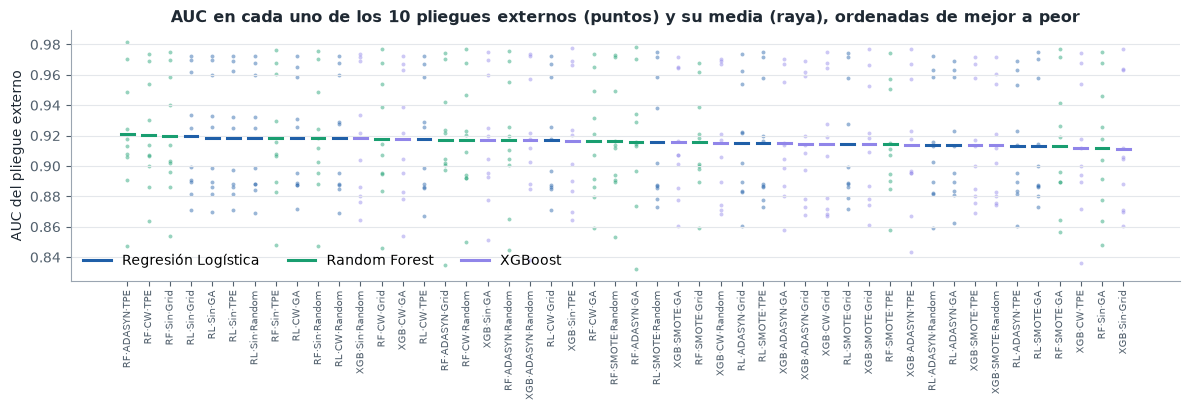

DE media de un procedimiento entre pliegues:     0.0397
DE de las medias entre los 48 procedimientos:    0.0023
Rango de las medias (mejor − peor):              0.0093


In [29]:
fig, ax = plt.subplots(figsize=(12, 4.2))
orden = resumen.sort_values("auc_media", ascending=False)["combo"].tolist()
for k, c in enumerate(orden):
    v = pliegues.loc[pliegues.combo == c, "auc"].to_numpy()
    m = c.split("|")[0]
    ax.scatter(np.full(len(v), k), v, s=8, color=config.COLOR_MODELO[m], alpha=0.45, linewidth=0)
    ax.plot([k - 0.3, k + 0.3], [v.mean()] * 2, color=config.COLOR_MODELO[m], lw=2.2)
ax.set_xticks(range(len(orden)),
              ["·".join(CORTO[p] for p in c.split("|")) for c in orden], rotation=90, fontsize=7)
ax.set_ylabel("AUC del pliegue externo")
ax.set_title("AUC en cada uno de los 10 pliegues externos (puntos) y su media (raya), "
             "ordenadas de mejor a peor")
for m in config.MODELOS:
    ax.plot([], [], color=config.COLOR_MODELO[m], lw=2.2, label=N[m])
ax.legend(ncol=3, loc="lower left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

de_dentro = resumen["auc_de"].mean()
de_entre = resumen["auc_media"].std(ddof=1)
rango = resumen["auc_media"].max() - resumen["auc_media"].min()
print(f"DE media de un procedimiento entre pliegues:     {de_dentro:.4f}")
print(f"DE de las medias entre los 48 procedimientos:    {de_entre:.4f}")
print(f"Rango de las medias (mejor − peor):              {rango:.4f}")

### Sensibilidad a la semilla

Para las tres combinaciones finales se repite la búsqueda completa sobre el entrenamiento con cinco semillas distintas (la semilla cambia los pliegues internos, el muestreador del optimizador, el sobremuestreo y la aleatoriedad del modelo) y se mide la AUC en prueba de cada modelo resultante. Es una medida de cuánto depende el resultado de la suerte del procedimiento, no de la elección del modelo.

In [30]:
def sensibilidad_semillas():
    filas = []
    for m, f in finales.items():
        for s in range(5):
            res = opt.buscar(f["metodo"], m, f["balanceo"], X_train, y_train, semilla=s)
            pipe = modelos.construir_pipeline(m, f["balanceo"], semilla=s, **res.mejores_params)
            pipe.fit(X_train, y_train)
            filas.append({"modelo": m, "semilla": s, "auc_interna": res.mejor_score,
                          "auc_test": roc_auc_score(yt, pipe.predict_proba(X_test)[:, 1]),
                          "params": res.mejores_params})
    return pd.DataFrame(filas)

semillas = en_cache("semillas", sensibilidad_semillas, RECALCULAR)
semillas.groupby("modelo").agg(
    auc_interna_media=("auc_interna", "mean"), auc_interna_de=("auc_interna", "std"),
    auc_test_media=("auc_test", "mean"), auc_test_de=("auc_test", "std"),
    auc_test_min=("auc_test", "min"), auc_test_max=("auc_test", "max"),
).reindex(config.MODELOS).rename(index=N).round(4)

,auc_interna_media,auc_interna_de,auc_test_media,auc_test_de,auc_test_min,auc_test_max
modelo,,,,,,
Regresión Logística,0.9196,0.0049,0.9207,0.0024,0.9190,0.9235
Random Forest,0.9186,0.0007,0.9235,0.0043,0.9182,0.9299
XGBoost,0.9184,0.0016,0.9251,0.0035,0.9207,0.9294


La desviación estándar media de un procedimiento entre pliegues (0,040) es **diecisiete veces mayor** que la desviación entre las medias de los 48 procedimientos (0,002), y más de cuatro veces mayor que la distancia entre el mejor y el peor (0,009). La variabilidad entre pacientes domina por completo la variabilidad entre métodos: con 67 pacientes por pliegue, un pliegue "difícil" (con más GBM de perfil `IDH1` mutado, como el paciente 576) baja la AUC de todos los procedimientos a la vez, y uno fácil la sube, sin cambiar su orden.

La sensibilidad a la semilla apunta en la misma dirección. Repetir la búsqueda con cinco semillas cambia la AUC de prueba en ±0,002 en la regresión logística, ±0,004 en Random Forest y ±0,003 en XGBoost (rango 0,918–0,930). El más sensible es Random Forest, en el que se suman dos fuentes de azar que dependen de la semilla: el sobremuestreo de ADASYN y el *bagging* de los árboles. En los tres casos la variación por semilla es del mismo orden que las diferencias entre modelos, así que ninguna diferencia observada puede atribuirse con seguridad a la elección del modelo sin una prueba formal.

## 2.11 Comparación estadística

Con 48 combinaciones hay $\binom{48}{2} = 1\,128$ pares posibles; contrastarlos uno a uno con $\alpha = 0{,}05$ produciría unos 56 falsos positivos solo por azar. Por eso la comparación sigue una estrategia jerárquica:

1. **Prueba ómnibus de Friedman** sobre los rangos de cada combinación en cada pliegue externo (los pliegues son los bloques: las 48 combinaciones se evaluaron sobre los mismos pliegues). $H_0$: todas tienen el mismo rango promedio. Se reporta también la corrección de Iman-Davenport, menos conservadora.
2. Si se rechaza, **post-hoc de Nemenyi** con su **diferencia crítica (CD)**: dos procedimientos cuyos rangos promedio difieren menos que la CD son estadísticamente indistinguibles, con control conjunto del error tipo I.
3. **Comparaciones dirigidas** entre los tres modelos finales con la **prueba de DeLong** sobre el conjunto de prueba, ajustadas por Holm, con intervalos **bootstrap BCa**.
4. **Tamaño del efecto** (delta de Cliff) para todas las comparaciones, sean o no significativas.

### Prueba de Friedman y diferencia crítica sobre las 48 combinaciones

Friedman: χ²_F(47) = 32.65, p = 9.45e-01
Iman-Davenport: F_F = 0.67, p = 9.53e-01
Diferencia crítica de Nemenyi (k = 48, N = 10): CD = 24.88


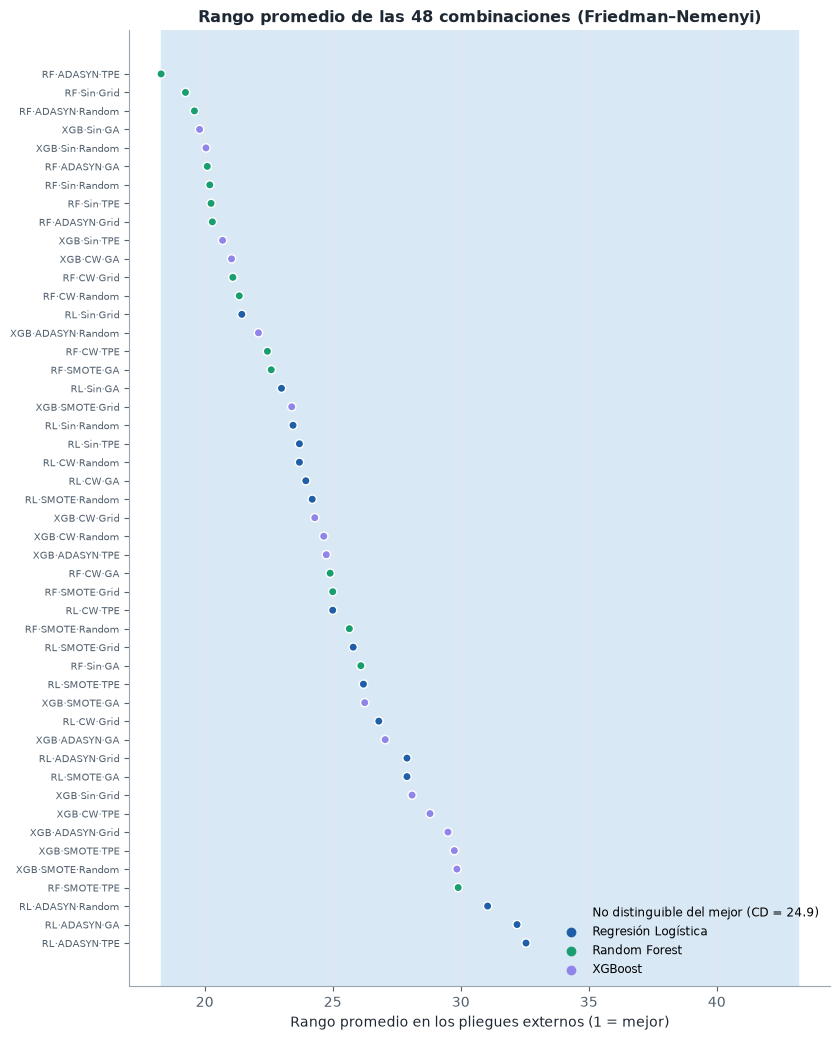

In [31]:
etiqueta = lambda c: "·".join(CORTO[p] for p in c.split("|"))
matriz = pliegues.pivot(index="pliegue", columns="combo", values="auc")
fr = ev.friedman(matriz)
cd48 = ev.diferencia_critica(fr["k"], fr["N"])
print(f"Friedman: χ²_F({fr['gl']}) = {fr['chi2']:.2f}, p = {fr['p']:.2e}")
print(f"Iman-Davenport: F_F = {fr['F_ID']:.2f}, p = {fr['p_ID']:.2e}")
print(f"Diferencia crítica de Nemenyi (k = {fr['k']}, N = {fr['N']}): CD = {cd48:.2f}")

rangos48 = fr["rangos"].rename(index=etiqueta)
colores48 = {etiqueta(c): config.COLOR_MODELO[c.split("|")[0]] for c in matriz.columns}
fig, ax = plt.subplots(figsize=(8.5, 10.5))
gr.rangos_con_cd(rangos48, cd48, colores48, ax=ax,
                 titulo="Rango promedio de las 48 combinaciones (Friedman–Nemenyi)")
for m in config.MODELOS:
    ax.scatter([], [], color=config.COLOR_MODELO[m], label=N[m])
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()

La prueba ómnibus **no rechaza** la hipótesis nula: $\chi^2_F(47) = 32{,}7$, $p = 0{,}94$. No hay evidencia de que alguna de las 48 combinaciones rinda distinto de las demás. Por el protocolo jerárquico, el análisis *post-hoc* sobre las 48 no procede; el gráfico se incluye solo como descripción: los rangos promedio van de 18,1 a 32,6 y la diferencia crítica de Nemenyi con 48 procedimientos y 10 bloques es de 24,9 rangos, así que todas las combinaciones caen dentro de la banda de "indistinguibles del mejor".

### Análisis por factor

Con 48 procedimientos y 10 bloques la CD es enorme. El diseño factorial permite una pregunta más precisa: para estudiar un factor (modelo, balanceo u optimizador), cada combinación de los otros dos factores con cada pliegue forma un bloque. Así, por ejemplo, los cuatro optimizadores se comparan en 120 bloques (3 modelos × 4 balanceos × 10 pliegues) y la prueba gana mucha potencia. La salvedad es que los bloques que comparten pliegue no son del todo independientes.

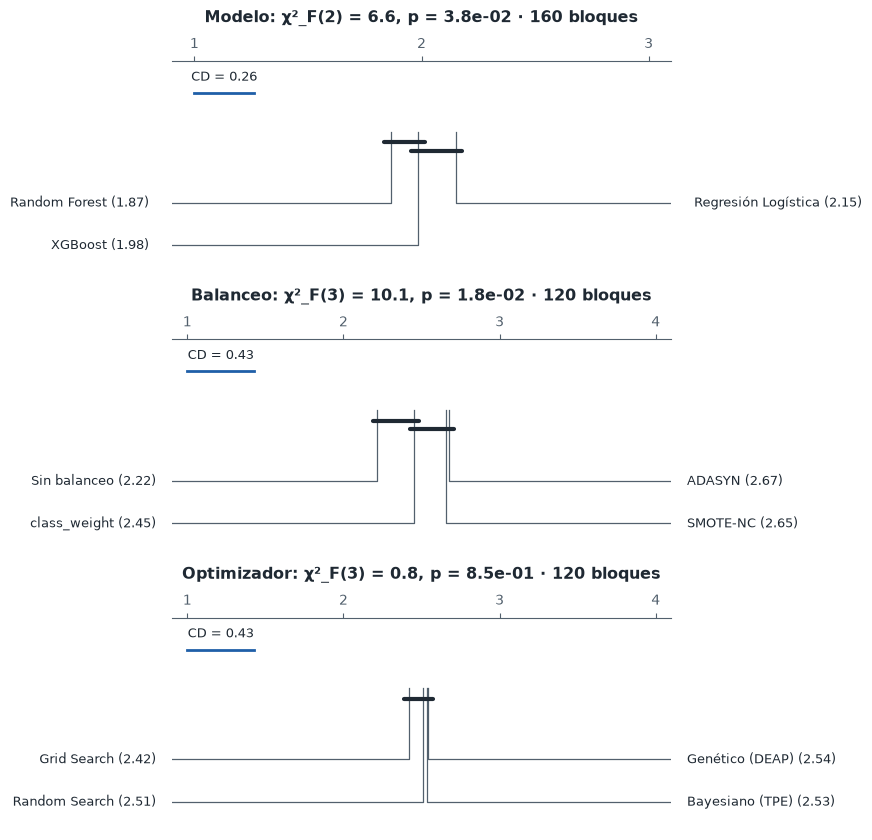

,Bloques,k,χ²_F,p,CD,Rangos promedio
Factor,,,,,,
Modelo,160,3,6.56,3.76e-02,0.262,"Random Forest 1.87, XGBoost 1.98, Regresión Lo..."
Balanceo,120,4,10.07,1.79e-02,0.428,"Sin balanceo 2.22, class_weight 2.45, SMOTE-NC..."
Optimizador,120,4,0.78,8.54e-01,0.428,"Grid Search 2.42, Random Search 2.51, Bayesian..."


p-valores de Nemenyi entre modelos


,Random Forest,XGBoost,Regresión Logística
Random Forest,1.0000,0.5377,0.0295
XGBoost,0.5377,1.0000,0.2999
Regresión Logística,0.0295,0.2999,1.0000


p-valores de Nemenyi entre optimizadores


,Grid Search,Random Search,Bayesiano (TPE),Genético (DEAP)
Grid Search,1.0000,0.9466,0.8971,0.8767
Random Search,0.9466,1.0000,0.9988,0.9972
Bayesiano (TPE),0.8971,0.9988,1.0000,1.0000
Genético (DEAP),0.8767,0.9972,1.0000,1.0000


In [32]:
factores = {"modelo": config.MODELOS, "balanceo": config.BALANCEOS, "metodo": config.OPTIMIZADORES}
NOMBRE_FACTOR = {"modelo": "Modelo", "balanceo": "Balanceo", "metodo": "Optimizador"}
fig, axes = plt.subplots(3, 1, figsize=(9, 8.5))
filas_f = []
for ax, (factor, niveles) in zip(axes, factores.items()):
    otros = [f for f in factores if f != factor] + ["pliegue"]
    mat = pliegues.pivot_table(index=otros, columns=factor, values="auc")[niveles]
    r = ev.friedman(mat)
    cd = ev.diferencia_critica(r["k"], r["N"])
    gr.diagrama_cd(r["rangos"].rename(index=N), cd, ax=ax,
                   titulo=f"{NOMBRE_FACTOR[factor]}: χ²_F({r['gl']}) = {r['chi2']:.1f}, "
                          f"p = {r['p']:.1e} · {r['N']} bloques")
    filas_f.append({"Factor": NOMBRE_FACTOR[factor], "Bloques": r["N"], "k": r["k"], "χ²_F": round(r["chi2"], 2),
                    "p": f"{r['p']:.2e}", "CD": round(cd, 3),
                    "Rangos promedio": ", ".join(f"{N[i]} {v:.2f}" for i, v in r["rangos"].items())})
    if factor == "metodo":
        nem_opt = ev.nemenyi(r["rangos"], r["N"]).rename(index=N, columns=N)
    if factor == "modelo":
        nem_mod = ev.nemenyi(r["rangos"], r["N"]).rename(index=N, columns=N)
plt.tight_layout()
plt.show()
display(pd.DataFrame(filas_f).set_index("Factor"))
print("p-valores de Nemenyi entre modelos")
display(nem_mod.round(4))
print("p-valores de Nemenyi entre optimizadores")
nem_opt.round(4)

Al estudiar cada factor por separado, con más bloques, aparecen señales en el modelo y en el balanceo, pero no en el optimizador:

- **Modelo** ($\chi^2_F(2) = 6{,}6$, $p = 0{,}038$): Random Forest tiene el mejor rango promedio (1,87, frente a 1,98 de XGBoost y 2,15 de la logística). El post-hoc de Nemenyi lo separa de la logística ($p = 0{,}030$) pero no de XGBoost ($p = 0{,}54$). Es una ventaja **consistente pero diminuta**: Random Forest gana más pliegues, por márgenes muy pequeños.
- **Balanceo** ($\chi^2_F(3) = 10{,}1$, $p = 0{,}018$): "sin balanceo" tiene el mejor rango (2,22, frente a 2,45 de `class_weight` y 2,65–2,68 de SMOTE-NC y ADASYN). Es coherente con un desbalance leve: crear pacientes sintéticos no ayuda a ordenar y, si acaso, añade ruido. Aun así, las AUC medias por técnica difieren menos de 0,003.
- **Optimizador** ($\chi^2_F(3) = 0{,}8$, $p = 0{,}85$): no hay diferencias. Los cuatro rangos promedio están entre 2,42 y 2,54, y ninguna comparación de Nemenyi es significativa.

### Comparaciones dirigidas: DeLong sobre el conjunto de prueba

Las tres comparaciones por pares entre los modelos finales se contrastan con la prueba de DeLong, que tiene en cuenta que las dos AUC se miden sobre los mismos pacientes (y por tanto están correlacionadas). Los p-valores se ajustan por Holm-Bonferroni y la diferencia de AUC se acompaña de un intervalo bootstrap BCa pareado.

In [33]:
def dif_auc(y_, a, b):
    return roc_auc_score(y_, a) - roc_auc_score(y_, b)

pares = [("logistica", "random_forest"), ("logistica", "xgboost"), ("random_forest", "xgboost")]
filas = []
for a, b in pares:
    d = ev.delong(yt, proba_test[a], proba_test[b])
    lo, hi = ev.ic_bootstrap(dif_auc, yt, proba_test[a], proba_test[b])
    filas.append({"Modelo A": N[a], "Modelo B": N[b], "Diferencia de AUC (A − B)": d["diferencia"],
                  "IC 95 % bootstrap BCa": f"[{lo:+.3f}, {hi:+.3f}]", "z": d["z"], "p crudo": d["p"]})
delong_tab = pd.DataFrame(filas)
delong_tab["p ajustado (Holm)"] = ev.holm(delong_tab["p crudo"])
delong_tab.round(4)

,Modelo A,Modelo B,Diferencia de AUC (A − B),IC 95 % bootstrap BCa,z,p crudo,p ajustado (Holm)
0,Regresión Logística,Random Forest,-0.0023,"[-0.027, +0.019]",-0.2037,0.8386,1.0
1,Regresión Logística,XGBoost,-0.0067,"[-0.029, +0.015]",-0.6331,0.5267,1.0
2,Random Forest,XGBoost,-0.0044,"[-0.023, +0.013]",-0.4883,0.6254,1.0


### Intervalos de confianza y tamaño del efecto

Los intervalos bootstrap BCa de la AUC en prueba de cada modelo final se complementan con el delta de Cliff, una medida no paramétrica de dominancia coherente con el uso de rangos: $\delta = P(A > B) - P(A < B)$, interpretado con los umbrales de Romano et al. (2006) (|δ| < 0,147 despreciable; < 0,33 pequeño; < 0,474 mediano; grande en otro caso). Se calcula sobre las AUC de los 10 pliegues externos de las combinaciones seleccionadas y, de forma agregada, sobre todos los pliegues de cada familia y de cada optimizador.

In [34]:
ic = []
for m in config.MODELOS:
    for met, f_ in [("AUC", roc_auc_score),
                    ("Recall (GBM)", lambda y_, p: np.mean(p[y_ == 1] >= 0.5))]:
        lo, hi = ev.ic_bootstrap(f_, yt, proba_test[m])
        ic.append({"Modelo": N[m], "Métrica": met, "Estimación": f_(yt, proba_test[m]),
                   "IC 95 % inferior": lo, "IC 95 % superior": hi})
display(pd.DataFrame(ic).set_index(["Modelo", "Métrica"]).round(3))

efectos = []
sel_auc = {m: pliegues.loc[pliegues.combo == exp.id_combo(m, f["balanceo"], f["metodo"]), "auc"].to_numpy()
           for m, f in finales.items()}
for a, b in pares:
    d1 = ev.delta_cliff(sel_auc[a], sel_auc[b])
    d2 = ev.delta_cliff(pliegues.loc[pliegues.modelo == a, "auc"], pliegues.loc[pliegues.modelo == b, "auc"])
    efectos.append({"Comparación": f"{N[a]} vs {N[b]}",
                    "δ combinaciones seleccionadas": f"{d1:+.3f} ({ev.magnitud_cliff(d1)})",
                    "δ todas las combinaciones de la familia": f"{d2:+.3f} ({ev.magnitud_cliff(d2)})"})
for o in ["grid", "bayesiano", "genetico"]:
    d2 = ev.delta_cliff(pliegues.loc[pliegues.metodo == o, "auc"], pliegues.loc[pliegues.metodo == "random", "auc"])
    efectos.append({"Comparación": f"{N[o]} vs Random Search", "δ combinaciones seleccionadas": "—",
                    "δ todas las combinaciones de la familia": f"{d2:+.3f} ({ev.magnitud_cliff(d2)})"})
pd.DataFrame(efectos).set_index("Comparación")

Estimación  IC 95 % inferior  \
Modelo              Métrica                                      
Regresión Logística AUC                0.923             0.875   
                    Recall (GBM)       0.914             0.823   
Random Forest       AUC                0.926             0.878   
                    Recall (GBM)       0.914             0.818   
XGBoost             AUC                0.930             0.888   
                    Recall (GBM)       0.886             0.794   

                                  IC 95 % superior  
Modelo              Métrica                         
Regresión Logística AUC                      0.957  
                    Recall (GBM)             0.968  
Random Forest       AUC                      0.957  
                    Recall (GBM)             0.969  
XGBoost             AUC                      0.962  
                    Recall (GBM)             0.948

,δ combinaciones seleccionadas,δ todas las combinaciones de la familia
Comparación,,
Regresión Logística vs Random Forest,-0.080 (despreciable),-0.074 (despreciable)
Regresión Logística vs XGBoost,+0.060 (despreciable),+0.023 (despreciable)
Random Forest vs XGBoost,+0.100 (despreciable),+0.059 (despreciable)
Grid Search vs Random Search,—,-0.014 (despreciable)
Bayesiano (TPE) vs Random Search,—,-0.008 (despreciable)
Genético (DEAP) vs Random Search,—,-0.017 (despreciable)


Ninguna comparación dirigida entre los modelos finales es significativa: las diferencias de AUC en prueba son de 0,002 a 0,007, con p-valores de DeLong entre 0,53 y 0,84 (1,0 tras el ajuste de Holm), y los tres intervalos bootstrap de la diferencia contienen el cero con holgura. Los tamaños del efecto confirman que la cuestión no es solo de potencia: el delta de Cliff es **despreciable** ($|\delta| \leq 0{,}10$) en todas las comparaciones entre modelos y entre optimizadores, tanto para las combinaciones seleccionadas como para todas las de cada familia. Incluso la ventaja de Random Forest que detectó Friedman por factores corresponde a $\delta = 0{,}06$–$0{,}10$: Random Forest gana un poco más de la mitad de los enfrentamientos, por márgenes que no tienen relevancia práctica.

La conclusión estadística es que, con estos datos, **los tres modelos son equivalentes en capacidad discriminativa**, con una AUC de prueba en torno a 0,92–0,93 (IC 95 % ≈ [0,88, 0,96]) y un recall de GBM del 89–91 % (IC 95 % ≈ [0,79, 0,97]). La elección entre ellos debe hacerse por otros criterios: interpretabilidad, calibración, costo y estabilidad.

## 2.12 ¿Cuántas variables hacen falta? Panel reducido

El objetivo general del proyecto es identificar el **subconjunto mínimo** de factores clínicos y mutaciones que conserva la capacidad de clasificar el grado tumoral, para evitar pruebas moleculares innecesarias. Para responderlo sin fuga de información, el ranking de variables se construye **dentro de cada pliegue externo**: se ajusta XGBoost con sus hiperparámetros finales sobre el pliegue de entrenamiento, se ordenan las variables por su |SHAP| medio en ese pliegue y se entrena el mejor procedimiento con las $k$ primeras. La AUC se mide en el pliegue de validación, que no intervino en el ranking.

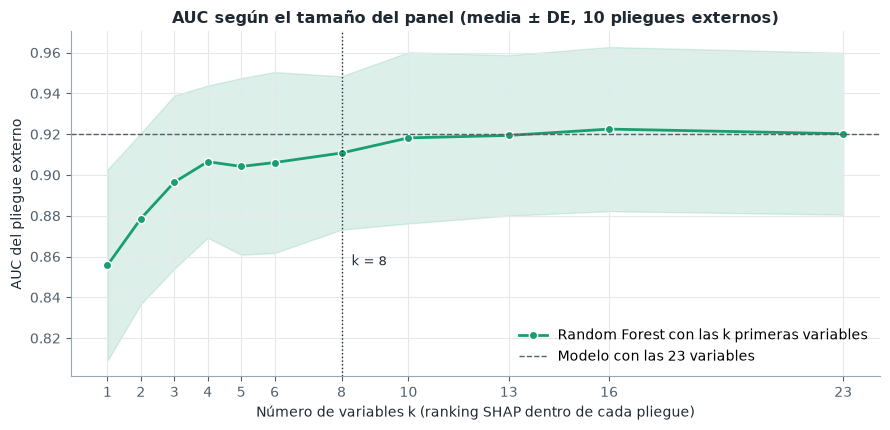

,Pliegues en que entra al top-8,Posición media en el ranking
IDH1,10,1.0
Age_at_diagnosis,10,2.1
TP53,10,2.9
PTEN,10,4.2
NF1,10,5.0
CIC,9,6.9
ATRX,8,7.6
IDH2,7,7.4
EGFR,4,8.5
Race_binary,2,10.5


k,1,2,3,4,5,6,8,10,13,16,23
auc,0.8557,0.8786,0.8965,0.9065,0.9042,0.9061,0.9108,0.9182,0.9194,0.9225,0.9202
de,0.0468,0.0419,0.0425,0.0373,0.0433,0.0444,0.0376,0.0420,0.0393,0.0402,0.0397
recall,0.9328,0.9010,0.8974,0.9116,0.9080,0.9185,0.9185,0.9220,0.9220,0.9220,0.9292


In [35]:
KS = [1, 2, 3, 4, 5, 6, 8, 10, 13, 16, 23]

def curva_panel():
    externo = StratifiedKFold(config.K_EXTERNO, shuffle=True, random_state=config.SEED)
    fx, fm = finales["xgboost"], finales[mejor]
    filas, rankings = [], []
    for i, (tr, va) in enumerate(externo.split(X_train, y_train)):
        Xtr, ytr = X_train.iloc[tr], y_train.iloc[tr]
        Xva, yva = X_train.iloc[va], y_train.iloc[va]
        px = modelos.construir_pipeline("xgboost", fx["balanceo"], **fx["params"]).fit(Xtr, ytr)
        imp = np.abs(shap_xgb(px, Xtr)[0]).mean(0)
        orden_ = [NOMBRES_VAR[j] for j in np.argsort(imp)[::-1]]
        rankings.append(orden_)
        for k in KS:
            pipe = modelos.construir_pipeline(mejor, fm["balanceo"], columnas=orden_[:k], **fm["params"])
            pipe.fit(Xtr, ytr)
            p = pipe.predict_proba(Xva)[:, 1]
            filas.append({"pliegue": i, "k": k, "auc": roc_auc_score(yva, p),
                          "recall": np.mean(p[yva.to_numpy() == 1] >= 0.5)})
    return pd.DataFrame(filas), rankings

panel, rankings = en_cache("panel_reducido", curva_panel, RECALCULAR)
pc = panel.groupby("k").agg(auc=("auc", "mean"), de=("auc", "std"), recall=("recall", "mean"))
completo = pc.loc[23, "auc"]
# Regla de un error estándar: el k más pequeño cuya AUC media no es inferior a la del
# modelo completo menos un error estándar (DE entre pliegues / raíz de 10)
k_min = int(pc.index[(pc.auc >= completo - pc.loc[23, "de"] / np.sqrt(config.K_EXTERNO))].min())

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.fill_between(pc.index, pc.auc - pc.de, pc.auc + pc.de, color=config.COLOR_MODELO[mejor], alpha=0.15)
ax.plot(pc.index, pc.auc, "-o", color=config.COLOR_MODELO[mejor], lw=2, markeredgecolor="white",
        label=f"{N[mejor]} con las k primeras variables")
ax.axhline(completo, color=gr.TINTA_2, ls="--", lw=1, label="Modelo con las 23 variables")
ax.axvline(k_min, color=gr.TINTA, lw=1, ls=":")
ax.text(k_min + 0.3, pc.auc.min(), f"k = {k_min}", fontsize=9, color=gr.TINTA)
ax.set_xlabel("Número de variables k (ranking SHAP dentro de cada pliegue)")
ax.set_ylabel("AUC del pliegue externo")
ax.set_title("AUC según el tamaño del panel (media ± DE, 10 pliegues externos)")
ax.set_xticks(KS)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

frecuencia = pd.Series([v for r in rankings for v in r[:k_min]]).value_counts()
display(pd.DataFrame({"Pliegues en que entra al top-%d" % k_min: frecuencia,
                      "Posición media en el ranking": [np.mean([r.index(v) + 1 for r in rankings])
                                                       for v in frecuencia.index]}).round(1))
pc.round(4).T

La curva responde a la pregunta central del proyecto. Con `IDH1`, la edad al diagnóstico, `TP53` y `PTEN` el modelo alcanza una AUC de 0,906 ± 0,037, frente a 0,920 ± 0,040 con las 23: **cuatro variables conservan casi toda la capacidad discriminativa**. Según la regla de un error estándar, sin embargo, el panel más pequeño indistinguible del completo es el de **ocho variables** ($k = 8$, AUC 0,911 ± 0,038): con cuatro, la AUC queda 0,001 por debajo del umbral (0,908). La ganancia grande ocurre hasta la cuarta variable: solo con `IDH1` la AUC es 0,856, con `IDH1` y la edad 0,879, y con las cuatro 0,906; las siguientes añaden poco y de forma irregular (con cinco y seis variables la AUC incluso baja ligeramente).

El ranking es estable: `IDH1` ocupa el primer puesto en los 10 pliegues externos, y la edad, `TP53` y `PTEN` ocupan de media los puestos 2 a 4 (posiciones medias 2,1, 2,9 y 4,2). Las ocho variables del panel ampliado (`IDH1`, la edad, `TP53`, `PTEN`, `NF1`, `CIC`, `ATRX` e `IDH2`) entran en el top 8 en al menos 7 de los 10 pliegues, aunque cada ranking se calculó sin ver los datos de validación. Coincide con las variables de mayor asociación del EDA, salvo que `TP53` sube por delante de `ATRX` y `CIC`, cuya información queda en buena parte contenida en `IDH1` y `TP53`.

En términos prácticos, la clasificación LGG/GBM que logra un panel de 20 genes se obtiene casi igual con la edad del paciente y el estado mutacional de tres genes (`IDH1`, `TP53`, `PTEN`), y sin pérdida apreciable con siete genes más la edad. Estos genes pueden evaluarse con un panel dirigido o, en el caso de `IDH1` R132H, con inmunohistoquímica.

### Archivos para el dashboard

Las tablas que necesitará el tablero de Dash se exportan a `jbook/resultados/` en formato CSV, de modo que la aplicación no tenga que reentrenar nada ni depender de las versiones exactas de las librerías de modelado.

In [36]:
d = config.DIR_RESULTADOS
pd.DataFrame({"indice_dataset": X_test.index, "grade": yt,
              **{f"proba_{m}": proba_test[m] for m in config.MODELOS}}).to_csv(d / "predicciones_test.csv", index=False)
metricas_test.reset_index().to_csv(d / "metricas_test.csv", index=False)
importancia.rename_axis("variable").reset_index().to_csv(d / "importancia_shap.csv", index=False)
pd.DataFrame(sv_xgb, columns=NOMBRES_VAR).assign(base=base_xgb).to_csv(d / "shap_xgboost.csv", index=False)
pc.reset_index().to_csv(d / "panel_reducido.csv", index=False)
bloques.to_csv(d / "eficiencia_optimizadores.csv", index=False)
recal.to_csv(d / "recalibracion.csv", index=False)
sorted(p.name for p in d.glob("*.csv"))

['eficiencia_optimizadores.csv',
 'experimentos.csv',
 'importancia_shap.csv',
 'metricas_test.csv',
 'oof.csv',
 'panel_reducido.csv',
 'pliegues.csv',
 'predicciones_test.csv',
 'recalibracion.csv',
 'shap_xgboost.csv']

## 2.13 Conclusiones

1. **El grado del glioma se predice bien con variables clínicas y mutacionales.** Los tres modelos alcanzan una AUC de 0,92 en validación anidada y de 0,92–0,93 en el conjunto de prueba, con un recall de GBM del 89–91 %. La AUC de prueba coincide con la estimación de la validación anidada, de modo que el procedimiento no sobreestimó el desempeño.

2. **Los tres modelos son estadísticamente equivalentes.** La prueba de Friedman no detecta diferencias entre las 48 combinaciones ($p = 0{,}94$), DeLong no distingue entre los modelos finales ($p_\text{Holm} = 1$) y todos los tamaños de efecto son despreciables. La variación entre pliegues (DE ≈ 0,04) es diecisiete veces mayor que la variación entre procedimientos.

3. **Si hay que elegir uno, la regresión logística con regularización L1.** Ante modelos equivalentes en discriminación decide el resto: la logística es estable ante la semilla, está razonablemente calibrada (y la recalibración isotónica la deja casi perfecta), se entrena en milisegundos, descarta por sí misma 10 de las 23 variables y sus coeficientes tienen lectura directa. XGBoost es la alternativa si se quieren captar efectos no lineales de la edad, y Random Forest requiere recalibrar sus probabilidades.

4. **El balanceo no mejora la discriminación.** Con un desbalance de 1,38:1, SMOTE-NC, ADASYN y `class_weight` solo desplazan el punto de operación hacia más recall; por rangos, no balancear es incluso algo mejor ($p = 0{,}018$), aunque las AUC medias difieren menos de 0,003. `class_weight` desplaza el punto de operación sin costo adicional; SMOTE-NC multiplica por cinco el tiempo de cómputo.

5. **La optimización bayesiana es el método más eficiente.** TPE llega antes a buenas soluciones que Random y Grid Search, con diferencias pequeñas pero significativas. El algoritmo genético encuentra soluciones internas igual de buenas, pero sufre convergencia prematura y tiene el mayor optimismo y la AUC externa más baja, aunque sin diferencias significativas: en la AUC externa los cuatro optimizadores son equivalentes ($p = 0{,}85$). *Successive Halving* y *early stopping* no aportan con datos de este tamaño, donde cada ajuste es barato.

6. **Un panel reducido basta.** `IDH1`, la edad, `TP53` y `PTEN` conservan casi toda la capacidad discriminativa del panel completo (AUC 0,906 frente a 0,920), y con ocho variables la diferencia ya no se distingue de la variación entre pliegues (regla de un error estándar, AUC 0,911). Es la respuesta al objetivo general del proyecto: un panel dirigido de entre tres y siete genes más la edad permitiría clasificar el grado tumoral casi con la misma precisión que los 20 genes.
7. **Los errores tienen una lectura clínica.** El peor error del modelo es un GBM con `IDH1`, `TP53` y `ATRX` mutados en un adulto joven, el perfil de un astrocitoma `IDH`-mutado de grado 4, que la clasificación de la OMS de 2021 ya separa del glioblastoma. Distinguir este subgrupo requeriría variables que el dataset no incluye.

**Limitaciones.** La cohorte es pequeña (839 pacientes, 168 de prueba) y predominantemente blanca (91 %), lo que limita la generalización a otras poblaciones. Las etiquetas siguen la clasificación histológica previa a 2021. Las comparaciones por factor usan bloques que comparten pliegue y no son del todo independientes. Por último, el límite entre cuatro y ocho variables es sensible al procedimiento: una ejecución anterior del mismo experimento (Linux, XGBoost 3.4.2) dio resultados idénticos en la regresión logística y en Random Forest pero distintos en XGBoost; en ella el mejor procedimiento fue XGBoost y la regla del error estándar señaló un panel de cuatro variables. Los resultados de este capítulo se obtuvieron con las versiones fijadas en `requirements-modelado.txt` (registradas en `resultados/entorno.json`).